# **Output Analysis - Thanh Long Le - 250307496**

**Measuring Performance Efficiency of Listed REITs in Western Europe using DEA: Integrating ESG Dimensions and an Extended Geometric DEA Framework**

This notebook is the analysis record for the dissertation. It starts from the raw Bloomberg extract and ends with every number reported in Chapters III, IV and V. Each reported value is recomputed here and compared with the value printed in the dissertation, and Section 9 lists all checks in one table.

| Section | Content | Dissertation |
|---|---|---|
| 1 | Setup, file paths and helper functions | |
| 2 | Data preparation: screening, unpivot to REIT-years, model input files, descriptive statistics | 3.1 to 3.4, Tables 3.2 and 3.3, Figure 3.1 |
| 3 | Classical DEA (M1, M2): Python re-estimation of the PIM-DEA results | 3.6 |
| 4 | Geometric DEA (M3 to M6, GE): Python re-estimation of the MATLAB results | 3.7, Appendix B |
| 5 | Combined scores, ranks and model-level summaries | Appendix A |
| 6 | Classical DEA benchmark results | 4.1, Tables 4.1 to 4.3, Figure 4.1 |
| 7 | Geometric DEA results and the full extension | 4.2 to 4.5, Tables 4.4 to 4.9, Figure 4.2 |
| 8 | Supporting analysis for the Discussion | 5.1 to 5.6, Appendix D |
| 9 | Verification summary and exported files | |

**Where each result comes from**

* M1 and M2 were estimated in PIM-DEA. M3 to M6 were estimated in MATLAB (`GDEA_restrictions_uncertain.m` and `dea_ahp.m`). The reported scores and weights are read from those output files.
* Every model is also re-estimated here in Python with `scipy.optimize.linprog`, so the scores can be reproduced without the original software.
* GE (equal category weights) and the M1 re-run without ESG outputs exist only in Python, so their values come from this notebook.

**How to run:** keep this notebook next to the `data/` folder and run all cells from top to bottom (Kernel > Restart & Run All). Tables are written to `outputs/` and figures to `figures/`.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linprog
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FIG_DIR = Path("figures")
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

FILES = {
    "raw": DATA_DIR / "Raw_REIT_EU_full.csv",
    "dea_input": DATA_DIR / "Data for DEA (PIM-DEA input).xlsx",
    "gdea_input": DATA_DIR / "Data for G-DEA three groups.xlsx",
    "M1": DATA_DIR / "DEA without weight restrictions.xlsx",
    "M2": DATA_DIR / "DEA with weight restricitons.xlsx",
    "M3": DATA_DIR / "GDEA_2_groups_no_restrictions.xlsx",
    "M4": DATA_DIR / "GDEA_2_groups_with_restrictions.xlsx",
    "M5": DATA_DIR / "GDEA_3_groups_no_restrictions.xlsx",
    "M6": DATA_DIR / "GDEA_3_groups_with_restrictions.xlsx",
}
for key, path in FILES.items():
    assert path.exists(), f"Missing file for {key}: {path}"

MODELS = ["M1", "M2", "GE", "M3", "M4", "M5", "M6"]
INPUTS = ["IE", "OE"]
OUTPUTS = ["TA", "R", "ES", "SS", "GS"]
GDEA_COLS = ["Inv_IE", "Inv_OE", "R", "TA", "ES", "SS", "GS"]
EFF = 99.995  # a score that rounds to 100.00% is treated as efficient

plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10})
print("All input files found.")

All input files found.


In [2]:
CHECKS = []

def check(section, item, reported, computed, tol=0.006):
    """Compare a value printed in the dissertation with the value computed here."""
    if isinstance(reported, (list, tuple, set)):
        ok = sorted(map(str, reported)) == sorted(map(str, computed))
        rep, comp = ", ".join(map(str, reported)), ", ".join(map(str, computed))
    elif isinstance(reported, str):
        ok = str(reported) == str(computed)
        rep, comp = reported, computed
    else:
        ok = abs(float(reported) - float(computed)) <= tol
        rep, comp = reported, round(float(computed), 4)
    CHECKS.append({"Section": section, "Item": item, "Reported": rep,
                   "Computed": comp, "Match": "PASS" if ok else "CHECK"})
    print(f"[{'PASS' if ok else 'CHECK'}] {section} | {item}: reported {rep}, computed {comp}")


def summary_stats(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    n_eff = int((s >= EFF).sum())
    return pd.Series({"Observations": len(s), "Mean": s.mean(), "Median": s.median(),
                      "Q1": q1, "Q3": q3, "IQR": q3 - q1, "Min": s.min(), "Max": s.max(),
                      "Efficient DMUs": n_eff, "Share efficient (%)": 100 * n_eff / len(s)})


def score_bands(s):
    labels = ["0 to under 25%", "25 to under 50%", "50 to under 75%", "75 to under 100%", "100%"]
    below = pd.cut(s[s < EFF], bins=[0, 25, 50, 75, 100], right=False, labels=labels[:4])
    counts = below.value_counts(sort=False).reindex(labels[:4], fill_value=0)
    counts.loc["100%"] = int((s >= EFF).sum())
    out = counts.rename("Number of DMUs").to_frame()
    out["Share (%)"] = 100 * out["Number of DMUs"] / len(s)
    return out


def efficient(s):
    idx = s[s >= EFF].index
    return sorted(idx, key=lambda d: int(d[1:]))


def rho(a, b):
    return spearmanr(a, b)[0]


def plot_bands(s, model, fname):
    bands = score_bands(s)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.barh(bands.index, bands["Number of DMUs"], color="#2a78d6")
    for bar, c in zip(bars, bands["Number of DMUs"]):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(c), va="center")
    ax.set_xlabel("Number of REIT-year observations")
    ax.set_ylabel("Efficiency score range")
    ax.set_title(f"Distribution of REIT-years by {model} efficiency score range")
    ax.set_xlim(0, bands["Number of DMUs"].max() + 8)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=300)
    plt.show()
    return bands

## 2. Data Preparation (Sections 3.1 to 3.4)

### 2.1 Raw Bloomberg extract
The raw file has one row per REIT and one column per variable and year (wide layout). It holds the 39 REITs with Environmental, Social and Governance scores for all three years. Monetary values are converted to US$ million.

In [3]:
raw = pd.read_csv(FILES["raw"], header=None, skiprows=2)
var_order = ["TA", "R", "OE", "IE", "SS", "GS", "ES"]
raw.columns = ["Ticker", "REIT"] + [f"{v}_{y}" for v in var_order for y in (2022, 2023, 2024)]
for c in raw.columns[2:]:
    raw[c] = pd.to_numeric(raw[c].astype(str).str.replace(",", ""), errors="raise")

panel_raw = pd.wide_to_long(raw, stubnames=var_order, i="Ticker", j="Year", sep="_").reset_index()
for c in ["TA", "R", "OE", "IE"]:
    panel_raw[c] = panel_raw[c] / 1e6
panel_raw["OE_R"] = panel_raw["OE"] / panel_raw["R"]

print(f"REITs in raw file: {raw.shape[0]}, REIT-years: {len(panel_raw)}")
print("Missing values:", int(panel_raw[var_order].isna().sum().sum()))
check("3.1", "REITs with full ESG data", 39, raw.shape[0], 0)
panel_raw.head()

REITs in raw file: 39, REIT-years: 117
Missing values: 0
[PASS] 3.1 | REITs with full ESG data: reported 39, computed 39.0


,Ticker,Year,REIT,TA,R,OE,IE,SS,GS,ES,OE_R
0,LAND LN Equity,2022,LAND SECURITIES GROUP PLC,"12,895.00",704.00,504.00,69.00,6.74,8.74,4.82,0.72
1,BYG LN Equity,2022,BIG YELLOW GROUP PLC,"2,670.38",171.32,594.77,10.60,6.60,7.38,4.49,3.47
2,SHUR BB Equity,2022,SHURGARD SELF STORAGE LTD,"4,659.83",335.29,554.29,17.90,5.44,6.08,5.19,1.65
3,SGRO LN Equity,2022,SEGRO PLC,"17,348.00",669.00,"1,959.00",100.00,5.46,8.26,5.27,2.93
4,GFC FP Equity,2022,GECINA SA,"20,677.86",749.28,290.72,94.27,8.60,6.98,4.14,0.39


### 2.2 Data quality screen on operating expenses
A REIT is excluded in full when its operating expenses fall outside a plausible share of revenue in any year. The dissertation states the rule as "below 2% or above 200% of revenue".

In [4]:
ratio = panel_raw.pivot(index=["Ticker", "REIT"], columns="Year", values="OE_R")
ratio["min"] = ratio[[2022, 2023, 2024]].min(axis=1)
ratio["max"] = ratio[[2022, 2023, 2024]].max(axis=1)

def screen(lower, upper=2.0):
    fail = (ratio["min"] < lower) | (ratio["max"] > upper)
    return ratio.index[~fail].get_level_values("Ticker")

prepared_info = pd.read_excel(FILES["dea_input"], sheet_name="MAIN")
final_tickers = set(prepared_info["Hoi"])

for lower in (0.02, 0.04):
    kept = set(screen(lower))
    print(f"Lower bound {lower:.0%}: {len(kept)} REITs kept, {39 - len(kept)} excluded, "
          f"same set as the final sample: {kept == final_tickers}")

display_ratio = (100 * ratio[[2022, 2023, 2024]]).round(1)
display_ratio["In final sample"] = display_ratio.index.get_level_values("Ticker").isin(final_tickers)
display_ratio.sort_values("In final sample")

Lower bound 2%: 26 REITs kept, 13 excluded, same set as the final sample: False
Lower bound 4%: 25 REITs kept, 14 excluded, same set as the final sample: True


,Year,2022,2023,2024,In final sample
Ticker,REIT,,,,
SGRO LN Equity,SEGRO PLC,292.80,90.80,16.00,False
LMP LN Equity,LONDONMETRIC PROPERTY PLC,461.00,394.40,6.00,False
BBOX LN Equity,TRITAX BIG BOX REIT PLC,342.60,28.00,46.70,False
WEHB BB Equity,WERELDHAVE BELGIUM NV,3.90,2.80,53.00,False
BYG LN Equity,BIG YELLOW GROUP PLC,347.20,16.00,66.60,False
CARM FP Equity,CARMILA,1.40,49.80,9.50,False
COV FP Equity,COVIVIO,1.30,239.30,42.00,False
ICAD FP Equity,ICADE,1.90,7.20,3.10,False
DLN LN Equity,DERWENT LONDON PLC,169.40,220.20,1.50,False


In [5]:
cov = ratio.xs("COV FP Equity", level="Ticker").iloc[0]
check("3.1", "Covivio OE/R 2022 (%)", 1.3, 100 * cov[2022], 0.05)
check("3.1", "Covivio OE/R 2023 (%)", 239, 100 * cov[2023], 0.5)
check("3.1", "REITs kept by the rule as written (2% / 200%)", 25, len(screen(0.02)), 0)
check("3.1", "REITs excluded by the screen", 14, 39 - len(final_tickers), 0)
check("3.1", "REITs in final sample", 25, len(final_tickers), 0)
wehb = ratio.xs("WEHB BB Equity", level="Ticker").iloc[0]
print(f"\nWereldhave Belgium OE/R: {100 * wehb[2022]:.1f}%, {100 * wehb[2023]:.1f}%, {100 * wehb[2024]:.1f}%")

[PASS] 3.1 | Covivio OE/R 2022 (%): reported 1.3, computed 1.3493
[PASS] 3.1 | Covivio OE/R 2023 (%): reported 239, computed 239.2977
[CHECK] 3.1 | REITs kept by the rule as written (2% / 200%): reported 25, computed 26.0
[PASS] 3.1 | REITs excluded by the screen: reported 14, computed 14.0
[PASS] 3.1 | REITs in final sample: reported 25, computed 25.0

Wereldhave Belgium OE/R: 3.9%, 2.8%, 53.0%


> **Note on the threshold.** With a 2% lower bound the rule keeps 26 REITs, because Wereldhave Belgium (3.9%, 2.8% and 53.0% of revenue) passes it. The 25-REIT sample used in every model is reproduced exactly with a 4% lower bound. The lowest ratio in the final sample is 4.1% (Aedifica 2024). Either the text in Section 3.1 should say 4%, or the reason for excluding Wereldhave Belgium should be stated.

### 2.3 Unpivot the screened REITs into REIT-years
This follows the original data preparation notebook: the 25 retained REITs are kept in the wide Bloomberg layout, unpivoted from wide to long using the year row, pivoted back to one row per REIT-year, coded P1 to P75 (REITs in alphabetical ticker order, years 2022 to 2024) and converted to US$ million. The result is exported as `REITs EU for DEA Final.csv`, the file used to build the PIM-DEA and MATLAB inputs.

In [6]:
# Load the raw extract as in the original preparation notebook (first data row holds the years)
df = pd.read_csv(FILES["raw"])
df = df.drop(columns=["Name"])
years = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)
df = df[df["Hoi"].isin(final_tickers)].reset_index(drop=True)
print(f"REITs after screening: {len(df)}")

# Map every raw column (e.g. 'Tot Assets.1') to its year
mapping = pd.DataFrame({"raw_variable": df.columns, "year": years.values})

# Wide -> long
df_long = df.melt(id_vars=["Hoi"], var_name="raw_variable", value_name="Value")
df_long = df_long.merge(mapping, on="raw_variable", how="left")
df_long["Variable"] = df_long["raw_variable"].str.replace(r"\.\d+$", "", regex=True)
df_long = df_long.dropna(subset=["year"])
df_long["year"] = df_long["year"].astype(float).astype(int)

# Long -> wide: one row per REIT-year
df_new = df_long.pivot(index=["Hoi", "year"], columns="Variable", values="Value").reset_index()
df_new.columns.name = None
df_new

REITs after screening: 25


,Hoi,year,Env Scr,Gov Scr,Int Exp,OpEx,Revenue,Soc Scr,Tot Assets
0,AED BB Equity,2022,3.80,7.52,"37,845,000","85,421,000","277,066,000",7.18,"6,085,540,000"
1,AED BB Equity,2023,3.81,7.31,"99,384,000","143,921,000","321,367,000",7.18,"6,176,811,000"
2,AED BB Equity,2024,3.67,7.30,"51,877,000","14,219,000","347,110,000",7.18,"6,463,824,000"
3,ALTA FP Equity,2022,4.45,5.27,"47,400,000","213,300,000","2,942,300,000",8.05,"9,087,700,000"
4,ALTA FP Equity,2023,4.65,5.02,"71,400,000","777,300,000","2,623,300,000",8.46,"8,337,100,000"
...,...,...,...,...,...,...,...,...,...
70,XIOR BB Equity,2023,3.59,6.46,"39,324,000","67,978,000","232,722,000",7.18,"3,396,864,000"
71,XIOR BB Equity,2024,3.27,6.43,"57,762,000","30,995,000","358,407,000",7.18,"3,520,445,000"
72,YCPS SM Equity,2022,4.63,6.63,"11,455,000","10,147,000","72,595,000",0.62,"1,132,052,000"
73,YCPS SM Equity,2023,5.06,6.52,"14,274,000","34,530,000","82,807,000",1.17,"1,174,074,000"


In [7]:
df_final = df_new.sort_values(["Hoi", "year"]).reset_index(drop=True)
df_final.insert(0, "DMU", ["P" + str(i) for i in range(1, len(df_final) + 1)])
df_final = df_final[["DMU", "year", "Hoi", "Tot Assets", "Revenue", "Int Exp", "OpEx", "Env Scr", "Soc Scr", "Gov Scr"]]
df_final = df_final.rename(columns={"year": "Year", "Tot Assets": "TA", "Revenue": "R", "Int Exp": "IE",
                                    "OpEx": "OE", "Env Scr": "ES", "Soc Scr": "SS", "Gov Scr": "GS"})

numeric_cols = ["TA", "R", "IE", "OE", "ES", "SS", "GS"]
for col in numeric_cols:
    df_final[col] = pd.to_numeric(df_final[col].astype(str).str.replace(",", "", regex=False).str.strip(),
                                  errors="raise")

# Monetary variables in US$ million
monetary_cols = ["TA", "R", "IE", "OE"]
df_final[monetary_cols] = df_final[monetary_cols] / 1_000_000
df_final = df_final.rename(columns={c: f"{c} ($million)" for c in monetary_cols})

df_final.to_csv(OUT_DIR / "REITs EU for DEA Final.csv", index=False)
print(f"Rows: {len(df_final)} | missing values: {int(df_final.isna().sum().sum())}")
df_final.head(10)

Rows: 75 | missing values: 0


,DMU,Year,Hoi,TA ($million),R ($million),IE ($million),OE ($million),ES,SS,GS
0,P1,2022,AED BB Equity,"6,085.54",277.07,37.84,85.42,3.80,7.18,7.52
1,P2,2023,AED BB Equity,"6,176.81",321.37,99.38,143.92,3.81,7.18,7.31
2,P3,2024,AED BB Equity,"6,463.82",347.11,51.88,14.22,3.67,7.18,7.30
3,P4,2022,ALTA FP Equity,"9,087.70","2,942.30",47.40,213.30,4.45,8.05,5.27
4,P5,2023,ALTA FP Equity,"8,337.10","2,623.30",71.40,777.30,4.65,8.46,5.02
5,P6,2024,ALTA FP Equity,"8,400.00","2,682.70",96.00,233.00,4.63,8.39,5.19
6,P7,2022,ARG FP Equity,"4,439.25",168.84,22.49,33.20,1.42,3.97,5.14
7,P8,2023,ARG FP Equity,"4,071.14",186.66,66.58,373.11,1.45,3.95,5.79
8,P9,2024,ARG FP Equity,"4,262.29",201.86,54.87,118.08,1.93,3.95,5.06
9,P10,2022,BLND LN Equity,"9,842.00",410.00,81.00,471.00,4.46,7.81,7.73


### 2.4 Model input files and DMU codes
The unpivoted panel is turned into the two input files: the PIM-DEA workbook (raw data and the mean-scaled data used for M2) and the MATLAB workbook (costs inverted as 1/IE and 1/OE). Both are rebuilt here and compared with the files that were actually used.

In [8]:
dea_in = pd.read_excel(FILES["dea_input"], sheet_name=None)
gdea_book = pd.read_excel(FILES["gdea_input"], sheet_name=None)

num = df_final.drop(columns=["Year", "Hoi"]).set_index("DMU")
built_scaled = (num / num.mean()).add_suffix("_scaled_mean")
built_scaled.columns = [c.replace(" ($million)", "") for c in built_scaled.columns]
built_gdea = pd.DataFrame({"Inv_IE": 1 / num["IE ($million)"], "Inv_OE": 1 / num["OE ($million)"],
                           "R": num["R ($million)"], "TA": num["TA ($million)"],
                           "ES": num["ES"], "SS": num["SS"], "GS": num["GS"]})

used_main = dea_in["MAIN"].set_index("DMU")
check("2.4", "DMU codes, years and tickers match the files used", "True",
      str(df_final.set_index("DMU")[["Year", "Hoi"]].equals(used_main[["Year", "Hoi"]])))
gaps = {
    "PIM-DEA DATA": (num - dea_in["DATA"].set_index("DMU")[num.columns]).abs().max().max(),
    "PIM-DEA DATA_SCALED_MEAN": (built_scaled - dea_in["DATA_SCALED_MEAN"].set_index("DMU")[built_scaled.columns]).abs().max().max(),
    "MATLAB Data (G-DEA)": (built_gdea - gdea_book["Data"].set_index("DMU")[built_gdea.columns]).abs().max().max(),
}
display(pd.Series(gaps, name="Largest absolute difference").to_frame())
for k, v in gaps.items():
    check("2.4", f"Rebuilt {k} equals the file used", 0, v, 1e-9)

with pd.ExcelWriter(OUT_DIR / "Model_input_files_rebuilt.xlsx") as xw:
    used_main.reset_index().to_excel(xw, sheet_name="MAIN", index=False)
    num.reset_index().to_excel(xw, sheet_name="DATA", index=False)
    built_scaled.reset_index().to_excel(xw, sheet_name="DATA_SCALED_MEAN", index=False)
    built_gdea.reset_index().to_excel(xw, sheet_name="GDEA_Data", index=False)

[PASS] 2.4 | DMU codes, years and tickers match the files used: reported True, computed True


,Largest absolute difference
PIM-DEA DATA,0.00
PIM-DEA DATA_SCALED_MEAN,0.00
MATLAB Data (G-DEA),0.00


[PASS] 2.4 | Rebuilt PIM-DEA DATA equals the file used: reported 0, computed 0.0
[PASS] 2.4 | Rebuilt PIM-DEA DATA_SCALED_MEAN equals the file used: reported 0, computed 0.0
[PASS] 2.4 | Rebuilt MATLAB Data (G-DEA) equals the file used: reported 0, computed 0.0


In [9]:
data = (used_main.reset_index().rename(columns={"Hoi": "Ticker", "REIT Name": "REIT"})
        .merge(num.rename(columns={"TA ($million)": "TA", "R ($million)": "R",
                                   "IE ($million)": "IE", "OE ($million)": "OE"}).reset_index(), on="DMU")
        .set_index("DMU"))
gdea_in = built_gdea.loc[data.index]
data["OE_R"] = 100 * data["OE"] / data["R"]
data["IE_TA"] = 100 * data["IE"] / data["TA"]
data["REIT_name"] = data["REIT"].str.title()
print(f"REITs: {data['Ticker'].nunique()}, DMUs: {len(data)}, per year: {data.groupby('Year').size().to_dict()}")
check("3.2", "DMUs (REIT-years)", 75, len(data), 0)

REITs: 25, DMUs: 75, per year: {2022: 25, 2023: 25, 2024: 25}
[PASS] 3.2 | DMUs (REIT-years): reported 75, computed 75.0


In [10]:
vals = data[INPUTS + OUTPUTS]
print("Missing:", int(vals.isna().sum().sum()), "| zero:", int((vals == 0).sum().sum()),
      "| negative:", int((vals < 0).sum().sum()))
check("3.4", "Lowest OE/R in sample (%)", 4.1, data["OE_R"].min(), 0.05)
check("3.4", "Highest OE/R in sample (%)", 200, data["OE_R"].max(), 0.5)
check("3.4", "Median OE/R (%)", 35.9, data["OE_R"].median(), 0.05)

print("\nTable 3.2. Extract of the prepared dataset (US$ million)")
data[["REIT_name", "Year", "TA", "R", "IE", "OE", "ES", "SS", "GS"]].head()

Missing: 0 | zero: 0 | negative: 0
[PASS] 3.4 | Lowest OE/R in sample (%): reported 4.1, computed 4.0964
[PASS] 3.4 | Highest OE/R in sample (%): reported 200, computed 199.8907
[PASS] 3.4 | Median OE/R (%): reported 35.9, computed 35.8638

Table 3.2. Extract of the prepared dataset (US$ million)


,REIT_name,Year,TA,R,IE,OE,ES,SS,GS
DMU,,,,,,,,,
P1,Aedifica,2022,"6,085.54",277.07,37.84,85.42,3.80,7.18,7.52
P2,Aedifica,2023,"6,176.81",321.37,99.38,143.92,3.81,7.18,7.31
P3,Aedifica,2024,"6,463.82",347.11,51.88,14.22,3.67,7.18,7.30
P4,Altarea,2022,"9,087.70","2,942.30",47.40,213.30,4.45,8.05,5.27
P5,Altarea,2023,"8,337.10","2,623.30",71.40,777.30,4.65,8.46,5.02


### 2.5 Descriptive statistics (Table 3.3)

In [11]:
labels = {"TA": "Total Assets (US$m)", "R": "Revenue (US$m)", "IE": "Interest Expense (US$m)",
          "OE": "Operating Expenses (US$m)", "ES": "Environmental Score", "SS": "Social Score",
          "GS": "Governance Score"}
desc = data[["TA", "R", "IE", "OE", "ES", "SS", "GS"]].describe().T
desc = desc[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.columns = ["Mean", "SD", "Min", "Q1", "Median", "Q3", "Max"]
desc.index = desc.index.map(labels)
print("Table 3.3. Descriptive statistics (n = 75)")
display(desc)
desc.to_excel(OUT_DIR / "Table_3_3_descriptives.xlsx")

reported_t33 = {
    "Total Assets (US$m)": [6790.69, 10572.28, 282.71, 2283.25, 3396.86, 7043.92, 54636.00],
    "Revenue (US$m)": [499.58, 783.96, 23.67, 133.90, 212.50, 359.80, 3256.10],
    "Interest Expense (US$m)": [85.30, 176.38, 1.17, 21.71, 41.20, 69.07, 1058.00],
    "Operating Expenses (US$m)": [236.07, 456.12, 3.70, 32.10, 67.98, 225.00, 3063.60],
    "Environmental Score": [3.79, 1.16, 0.29, 3.02, 4.04, 4.64, 5.79],
    "Social Score": [6.24, 1.86, 0.62, 4.88, 6.64, 7.43, 9.64],
    "Governance Score": [6.68, 1.17, 4.64, 5.78, 6.76, 7.48, 8.95],
}
gap = (desc - pd.DataFrame(reported_t33, index=desc.columns).T).abs().max().max()
check("Table 3.3", "Largest gap across all 49 cells", 0, gap, 0.006)
largest = data["TA"].idxmax()
check("3.4", "Largest REIT-year", "Unibail-Rodamco-Westfield 2022",
      f"{data.loc[largest, 'REIT_name']} {data.loc[largest, 'Year']}")

Table 3.3. Descriptive statistics (n = 75)


,Mean,SD,Min,Q1,Median,Q3,Max
Total Assets (US$m),"6,790.69","10,572.28",282.71,"2,283.25","3,396.86","7,043.92","54,636.00"
Revenue (US$m),499.58,783.96,23.67,133.90,212.50,359.80,"3,256.10"
Interest Expense (US$m),85.30,176.38,1.17,21.71,41.20,69.07,"1,058.00"
Operating Expenses (US$m),236.07,456.12,3.70,32.10,67.98,225.00,"3,063.60"
Environmental Score,3.79,1.16,0.29,3.02,4.04,4.64,5.79
Social Score,6.24,1.86,0.62,4.88,6.64,7.43,9.64
Governance Score,6.68,1.17,4.64,5.78,6.76,7.48,8.95


[PASS] Table 3.3 | Largest gap across all 49 cells: reported 0, computed 0.005
[PASS] 3.4 | Largest REIT-year: reported Unibail-Rodamco-Westfield 2022, computed Unibail-Rodamco-Westfield 2022


### 2.6 Correlation matrix (Figure 3.1)

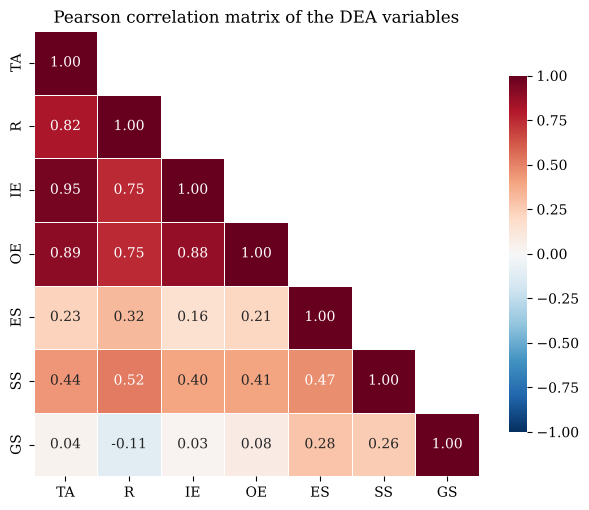

[PASS] 3.4 | Min input-output r: reported 0.75, computed 0.7461
[PASS] 3.4 | Max input-output r: reported 0.95, computed 0.9548
[PASS] 3.4 | r(TA, R): reported 0.82, computed 0.8168
[PASS] 3.4 | r(SS, R): reported 0.52, computed 0.5181
[PASS] 3.4 | r(SS, TA): reported 0.44, computed 0.4389
[PASS] 3.4 | Min r among ESG scores: reported 0.26, computed 0.2569
[PASS] 3.4 | Max r among ESG scores: reported 0.47, computed 0.4682


In [12]:
corr = data[["TA", "R", "IE", "OE", "ES", "SS", "GS"]].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation matrix of the DEA variables")
fig.tight_layout()
fig.savefig(FIG_DIR / "Figure_3_1_correlation_matrix.png", dpi=300)
plt.show()

io = corr.loc[["IE", "OE"], ["TA", "R"]].values
check("3.4", "Min input-output r", 0.75, io.min(), 0.005)
check("3.4", "Max input-output r", 0.95, io.max(), 0.005)
check("3.4", "r(TA, R)", 0.82, corr.loc["TA", "R"], 0.005)
check("3.4", "r(SS, R)", 0.52, corr.loc["SS", "R"], 0.005)
check("3.4", "r(SS, TA)", 0.44, corr.loc["SS", "TA"], 0.005)
esg = corr.loc[["ES", "SS", "GS"], ["ES", "SS", "GS"]].values[np.triu_indices(3, 1)]
check("3.4", "Min r among ESG scores", 0.26, esg.min(), 0.005)
check("3.4", "Max r among ESG scores", 0.47, esg.max(), 0.005)

In [13]:
m, s = len(INPUTS), len(OUTPUTS)
rule = max(m * s, 3 * (m + s))
print(f"Rule of thumb: max(m*s, 3(m+s)) = max({m * s}, {3 * (m + s)}) = {rule} DMUs; sample = {len(data)}")
check("3.4", "Minimum DMUs (rule of thumb)", 21, rule, 0)

Rule of thumb: max(m*s, 3(m+s)) = max(10, 21) = 21 DMUs; sample = 75
[PASS] 3.4 | Minimum DMUs (rule of thumb): reported 21, computed 21.0


## 3. Classical DEA: M1 and M2 (Section 3.6)

M1 is the output-oriented CCR model. M2 adds the restriction 0.25 ≤ W₂/W₁ ≤ 4 on the multiplier sums, after every variable is divided by its pooled sample mean. Both were run in PIM-DEA. The functions below solve the same models in Python.

In [14]:
def ccr_output_multiplier(X, Y, ratio_bounds=None):
    """Output-oriented CCR, multiplier form: min v'x_k s.t. u'y_k = 1, u'y_j - v'x_j <= 0.
    ratio_bounds = (L, U) adds L <= sum(u) / sum(v) <= U. Returns scores in % and weights."""
    n, m = X.shape
    s = Y.shape[1]
    scores, weights = np.zeros(n), np.zeros((n, m + s))
    for k in range(n):
        c = np.r_[X[k], np.zeros(s)]
        A, b = np.c_[-X, Y], np.zeros(n)
        if ratio_bounds is not None:
            lo, hi = ratio_bounds
            A = np.r_[A, [np.r_[lo * np.ones(m), -np.ones(s)]], [np.r_[-hi * np.ones(m), np.ones(s)]]]
            b = np.r_[b, 0, 0]
        res = linprog(c, A_ub=A, b_ub=b, A_eq=[np.r_[np.zeros(m), Y[k]]], b_eq=[1],
                      bounds=[(0, None)] * (m + s), method="highs")
        scores[k], weights[k] = 100 / res.fun, res.x
    return scores, weights


def ccr_output_envelopment(X, Y):
    """Output-oriented CCR, envelopment form: max phi s.t. X'lambda <= x_k, Y'lambda >= phi*y_k.
    Returns scores in % (100/phi) and the intensity matrix lambda (row k = peers of DMU k)."""
    n, m = X.shape
    s = Y.shape[1]
    scores, lambdas = np.zeros(n), np.zeros((n, n))
    for k in range(n):
        c = np.r_[-1, np.zeros(n)]
        A = np.r_[np.c_[np.zeros(m), X.T], np.c_[Y[k][:, None], -Y.T]]
        b = np.r_[X[k], np.zeros(s)]
        res = linprog(c, A_ub=A, b_ub=b, bounds=[(0, None)] * (n + 1), method="highs")
        scores[k], lambdas[k] = 100 / res.x[0], res.x[1:]
    return scores, lambdas

In [15]:
X, Y = data[INPUTS].values, data[OUTPUTS].values
scaled = dea_in["DATA_SCALED_MEAN"].set_index("DMU").loc[data.index]
Xs = scaled[["IE_scaled_mean", "OE_scaled_mean"]].values
Ys = scaled[["TA_scaled_mean", "R_scaled_mean", "ES_scaled_mean", "SS_scaled_mean", "GS_scaled_mean"]].values
assert np.allclose(Xs, X / X.mean(axis=0)) and np.allclose(Ys, Y / Y.mean(axis=0))
print("M2 input = every variable divided by its pooled mean (all means equal 1).")

py = {}
py["M1"], _ = ccr_output_multiplier(X, Y)
py["M1_env"], LAMBDA = ccr_output_envelopment(X, Y)
py["M2"], _ = ccr_output_multiplier(Xs, Ys, ratio_bounds=(0.25, 4))
py["M1_scaled"], _ = ccr_output_multiplier(Xs, Ys)

software = {}
for mdl in ["M1", "M2"]:
    eff = pd.read_excel(FILES[mdl], sheet_name="Efficiencies").rename(columns={"Name": "DMU", "Efficiency": "Score"})
    software[mdl] = eff.set_index("DMU")["Score"].loc[data.index]

comp = pd.DataFrame({
    "Max |Python - PIM-DEA| (pp)": [np.abs(py["M1"] - software["M1"]).max(),
                                     np.abs(py["M1_env"] - software["M1"]).max(),
                                     np.abs(py["M1_scaled"] - software["M1"]).max(),
                                     np.abs(py["M2"] - software["M2"]).max()]},
    index=["M1 (multiplier)", "M1 (envelopment)", "M1 on mean-scaled data", "M2"])
display(comp)
print("PIM-DEA reports scores to 2 decimals, so differences below 0.005 are rounding.")
check("3.6", "M1 Python vs PIM-DEA, max gap", 0, comp.iloc[0, 0], 0.006)
check("3.6", "M2 Python vs PIM-DEA, max gap", 0, comp.iloc[3, 0], 0.006)
check("3.4", "M1 unchanged by mean-scaling (CCR unit invariance)", 0, comp.iloc[2, 0], 0.006)

M2 input = every variable divided by its pooled mean (all means equal 1).


,Max |Python - PIM-DEA| (pp)
M1 (multiplier),0.00
M1 (envelopment),0.00
M1 on mean-scaled data,0.00
M2,0.00


PIM-DEA reports scores to 2 decimals, so differences below 0.005 are rounding.
[PASS] 3.6 | M1 Python vs PIM-DEA, max gap: reported 0, computed 0.0048
[PASS] 3.6 | M2 Python vs PIM-DEA, max gap: reported 0, computed 0.0049
[PASS] 3.4 | M1 unchanged by mean-scaling (CCR unit invariance): reported 0, computed 0.0048


## 4. Geometric DEA: M3 to M6 and GE (Section 3.7)

The two cost variables enter as reciprocals. For DMU k the model maximises θ subject to Σⱼ wⱼ ln(zⱼₚ / zⱼₖ) + θ ≤ 0 for every peer p and Σⱼ wⱼ = 1, and the score is exp(θ). Category restrictions are added as extra linear rows built exactly as in the MATLAB file `GDEA_restrictions_uncertain.m` (interval pairwise judgements, direct and indirect comparisons, widened to indicator level).

In [16]:
def hierarchy_constraints(group_sizes, lower, upper):
    """Python port of GDEA_restrictions_uncertain.m for a single pairwise matrix at level 2.
    lower/upper: {(i, j): value} for the upper-triangular interval judgements W_i / W_j."""
    g = len(group_sizes)
    a, w = np.ones((g, g)), np.ones((g, g))
    for (i, j), v in lower.items():
        a[i, j] = v
    for (i, j), v in upper.items():
        w[i, j] = v
    bl = np.triu(a) + np.tril(1 / a.T) - np.eye(g)
    bu = np.triu(w) + np.tril(1 / w.T) - np.eye(g)
    rows = []
    for i in range(g - 1):
        for j in range(i + 1, g):
            lo = np.r_[bl[i, :] * bu[:, j], bl[i, :] * bl[:, j]].min()
            hi = np.r_[bu[i, :] * bl[:, j], bu[i, :] * bu[:, j]].max()
            r1, r2 = np.zeros(g), np.zeros(g)
            r1[i], r1[j] = -1, lo
            r2[i], r2[j] = 1, -hi
            rows += [r1, r2]
    return np.repeat(np.array(rows), group_sizes, axis=1)


def gdea(Z, h=None):
    """Geometric DEA (dea_ahp.m). Z: positive data, more is better. Returns scores in % and weights."""
    n, k_ind = Z.shape
    logZ = np.log(Z)
    f = np.r_[np.zeros(k_ind), -1]
    scores, weights = np.zeros(n), np.zeros((n, k_ind))
    for k in range(n):
        A, b = np.c_[logZ - logZ[k], np.ones(n)], np.zeros(n)
        if h is not None:
            A = np.r_[A, np.c_[h, np.zeros(len(h))]]
            b = np.r_[b, np.zeros(len(h))]
        res = linprog(f, A_ub=A, b_ub=b, A_eq=[np.r_[np.ones(k_ind), 0]], b_eq=[1],
                      bounds=[(0, None)] * k_ind + [(None, None)], method="highs")
        scores[k], weights[k] = 100 * np.exp(res.x[-1]), res.x[:k_ind]
    return scores, weights

In [17]:
Z = gdea_in[GDEA_COLS].values
TWO, THREE = [2, 5], [2, 2, 3]   # [Resource-Cost | Performance], [Resource-Cost | Financial | ESG]

h_M4 = hierarchy_constraints(TWO, {(0, 1): 0.25}, {(0, 1): 4})
h_M6 = hierarchy_constraints(THREE, {(0, 1): 0.375, (0, 2): 0.5625, (1, 2): 1.25},
                             {(0, 1): 7.2, (0, 2): 12, (1, 2): 2})
h_GE = hierarchy_constraints(TWO, {(0, 1): 1}, {(0, 1): 1})

py_w = {}
py["M3"], py_w["M3"] = gdea(Z)
py["M4"], py_w["M4"] = gdea(Z, h_M4)
py["M5"], py_w["M5"] = gdea(Z)
py["M6"], py_w["M6"] = gdea(Z, h_M6)
ge_sqrt, py_w["GE"] = gdea(Z, h_GE)
py["GE_sqrt"] = ge_sqrt
py["GE"] = 100 * (ge_sqrt / 100) ** 2
print("Category weights under GE (cost / performance):",
      np.unique(py_w["GE"][:, :2].sum(axis=1).round(6)), np.unique(py_w["GE"][:, 2:].sum(axis=1).round(6)))

software_w = {}
for mdl in ["M3", "M4", "M5", "M6"]:
    book = pd.read_excel(FILES[mdl], sheet_name=None)
    software[mdl] = book["Efficiencies"].set_index("DMU")["Score"].loc[data.index]
    software_w[mdl] = book["Weights"].set_index("DMU").loc[data.index, GDEA_COLS]

comp_g = pd.Series({mdl: np.abs(py[mdl] - software[mdl]).max() for mdl in ["M3", "M4", "M5", "M6"]},
                   name="Max |Python - MATLAB| (pp)").to_frame()
display(comp_g)
for mdl in ["M3", "M4", "M5", "M6"]:
    check("3.7", f"{mdl} Python vs MATLAB, max gap", 0, comp_g.loc[mdl].iloc[0], 0.02)

Category weights under GE (cost / performance): [0.5] [0.5]


,Max |Python - MATLAB| (pp)
M3,0.00
M4,0.00
M5,0.01
M6,0.00


[PASS] 3.7 | M3 Python vs MATLAB, max gap: reported 0, computed 0.0011
[PASS] 3.7 | M4 Python vs MATLAB, max gap: reported 0, computed 0.0
[PASS] 3.7 | M5 Python vs MATLAB, max gap: reported 0, computed 0.0111
[PASS] 3.7 | M6 Python vs MATLAB, max gap: reported 0, computed 0.0


The Python and MATLAB scores agree to within 0.012 percentage points (M3 and M5 differ only at solver tolerance). Optimal weights are not unique in DEA, so Python can return a different weight vector with the same score. All weight figures reported in the dissertation therefore use the MATLAB weights. GE has no MATLAB file and uses the Python weights.

### 4.1 M6 bounds from the two judgements (Appendix B)

In [18]:
p_range, r_range = (0.25, 4), (1.25, 2)       # p = W2/W1, r = W2a/W2b
grid = [(p, r) for p in p_range for r in r_range]
w1_w2a = [(1 + r) / (p * r) for p, r in grid]
w1_w2b = [(1 + r) / p for p, r in grid]
print(f"W1/W2a in [{min(w1_w2a):.4f}, {max(w1_w2a):.4f}]")
print(f"W1/W2b in [{min(w1_w2b):.4f}, {max(w1_w2b):.4f}]")
check("App. B", "Lower bound W1/W2a", 0.375, min(w1_w2a), 1e-9)
check("App. B", "Upper bound W1/W2a", 7.2, max(w1_w2a), 1e-9)
check("App. B", "Lower bound W1/W2b", 0.5625, min(w1_w2b), 1e-9)
check("App. B", "Upper bound W1/W2b", 12, max(w1_w2b), 1e-9)

W1/W2a in [0.3750, 7.2000]
W1/W2b in [0.5625, 12.0000]
[PASS] App. B | Lower bound W1/W2a: reported 0.375, computed 0.375
[PASS] App. B | Upper bound W1/W2a: reported 7.2, computed 7.2
[PASS] App. B | Lower bound W1/W2b: reported 0.5625, computed 0.5625
[PASS] App. B | Upper bound W1/W2b: reported 12, computed 12.0


## 5. Combined Scores, Ranks and Summaries (Appendix A)

Reported scores come from the software files (PIM-DEA for M1 and M2, MATLAB for M3 to M6) and from Python for GE. Ranks use average ranks for ties, with rank 1 the highest score.

In [19]:
scores = pd.DataFrame({mdl: software[mdl] for mdl in ["M1", "M2", "M3", "M4", "M5", "M6"]})
scores.insert(2, "GE", py["GE"].round(2))
ranks = scores.rank(ascending=False, method="average")

appendix = data[["REIT_name", "Year"]].join(scores.round(2)).join(ranks.add_suffix("_rank"))
with pd.ExcelWriter(OUT_DIR / "Appendix_A_scores_and_ranks.xlsx") as xw:
    appendix.to_excel(xw, sheet_name="Scores and ranks")
    data[["Ticker", "REIT_name", "Year"]].to_excel(xw, sheet_name="DMU codes")
appendix.head(10)

,REIT_name,Year,M1,M2,GE,M3,M4,M5,M6,M1_rank,M2_rank,GE_rank,M3_rank,M4_rank,M5_rank,M6_rank
DMU,,,,,,,,,,,,,,,,
P1,Aedifica,2022,62.10,62.10,60.31,98.71,96.59,98.71,91.06,30.00,24.00,29.00,38.00,28.00,38.00,27.00
P2,Aedifica,2023,27.96,27.24,27.26,89.32,80.90,89.32,71.37,64.00,64.00,66.00,55.00,62.00,55.00,54.00
P3,Aedifica,2024,100.00,83.48,100.00,100.00,100.00,100.00,100.00,6.50,10.00,5.50,18.00,12.00,18.00,8.50
P4,Altarea,2022,100.00,100.00,100.00,100.00,100.00,100.00,100.00,6.50,2.50,5.50,18.00,12.00,18.00,8.50
P5,Altarea,2023,60.07,58.11,61.74,100.00,94.38,100.00,90.66,33.00,26.00,28.00,18.00,36.00,18.00,30.00
P6,Altarea,2024,80.05,68.88,73.59,100.00,98.63,100.00,96.03,18.00,16.00,22.00,18.00,27.00,18.00,21.00
P7,Argan,2022,86.20,84.74,84.13,93.30,93.30,93.28,88.28,16.00,9.00,17.00,51.00,42.00,51.00,35.00
P8,Argan,2023,18.34,18.34,18.20,65.72,61.54,65.72,57.20,74.00,73.00,73.00,73.00,75.00,73.00,72.00
P9,Argan,2024,30.28,30.28,29.51,62.63,62.31,62.63,60.72,59.00,59.00,63.00,74.00,73.00,74.00,69.00


In [20]:
summary = scores.apply(summary_stats).T
print("Summary of all models (%)")
display(summary)

spearman = scores.corr(method="spearman")
print("Spearman rank correlations")
display(spearman.round(3))

by_year = scores.join(data["Year"]).groupby("Year").median()
print("Median efficiency by year (%)")
display(by_year)

def category_shares(W):
    W = np.asarray(W)
    return pd.Series({"Resource-Cost": 100 * W[:, :2].sum(1).mean(),
                      "Financial (R, TA)": 100 * W[:, 2:4].sum(1).mean(),
                      "ESG (ES, SS, GS)": 100 * W[:, 4:].sum(1).mean()})

weights_used = {"GE": py_w["GE"], **{m: software_w[m].values for m in ["M3", "M4", "M5", "M6"]}}
shares = pd.DataFrame({m: category_shares(W) for m, W in weights_used.items()}).T
print("Average category weights (% of total weight)")
display(shares)

with pd.ExcelWriter(OUT_DIR / "Model_summaries.xlsx") as xw:
    summary.to_excel(xw, sheet_name="Summary")
    spearman.to_excel(xw, sheet_name="Spearman")
    by_year.to_excel(xw, sheet_name="Median by year")
    shares.to_excel(xw, sheet_name="Category weights")

Summary of all models (%)


,Observations,Mean,Median,Q1,Q3,IQR,Min,Max,Efficient DMUs,Share efficient (%)
M1,75.00,56.17,51.94,32.28,79.72,47.44,15.54,100.00,12.00,16.00
M2,75.00,49.93,44.03,31.64,64.22,32.58,15.54,100.00,4.00,5.33
GE,75.00,55.83,50.54,33.17,78.53,45.36,16.11,100.00,10.00,13.33
M3,75.00,93.47,98.71,88.75,100.00,11.25,61.94,100.00,35.00,46.67
M4,75.00,90.88,94.14,84.90,100.00,15.10,61.54,100.00,23.00,30.67
M5,75.00,93.47,98.71,88.75,100.00,11.25,61.94,100.00,35.00,46.67
M6,75.00,82.64,86.23,69.77,96.84,27.07,49.78,100.00,16.00,21.33


Spearman rank correlations


,M1,M2,GE,M3,M4,M5,M6
M1,1.00,0.95,0.99,0.50,0.68,0.50,0.73
M2,0.95,1.00,0.95,0.47,0.64,0.47,0.72
GE,0.99,0.95,1.00,0.54,0.70,0.54,0.76
M3,0.50,0.47,0.54,1.00,0.91,1.00,0.73
M4,0.68,0.64,0.70,0.91,1.00,0.91,0.85
M5,0.50,0.47,0.54,1.00,0.91,1.00,0.73
M6,0.73,0.72,0.76,0.73,0.85,0.73,1.00


Median efficiency by year (%)


,M1,M2,GE,M3,M4,M5,M6
Year,,,,,,,
2022,64.59,62.10,64.09,100.00,98.92,100.00,95.02
2023,40.49,38.86,42.01,97.75,94.14,97.75,76.64
2024,41.67,36.71,37.81,95.59,91.92,95.59,82.22


Average category weights (% of total weight)


,Resource-Cost,"Financial (R, TA)","ESG (ES, SS, GS)"
GE,50.00,39.30,10.70
M3,11.02,10.28,78.70
M4,22.39,16.41,61.20
M5,18.27,8.16,73.58
M6,33.25,37.56,29.19


## 6. Classical DEA Benchmark (Section 4.1)

### 6.1 Unrestricted CCR, M1 (Table 4.1 and Figure 4.1)

In [21]:
s1 = scores["M1"]
t41 = summary_stats(s1)
print("Table 4.1. Summary of efficiency results under M1")
display(t41.to_frame("M1"))
for item, rep, key in [("Mean (%)", 56.17, "Mean"), ("Median (%)", 51.94, "Median"), ("Q1 (%)", 32.28, "Q1"),
                       ("Q3 (%)", 79.72, "Q3"), ("Min (%)", 15.54, "Min"), ("Efficient DMUs", 12, "Efficient DMUs"),
                       ("Share efficient (%)", 16.00, "Share efficient (%)")]:
    check("Table 4.1", item, rep, t41[key])

Table 4.1. Summary of efficiency results under M1


,M1
Observations,75.00
Mean,56.17
Median,51.94
Q1,32.28
Q3,79.72
IQR,47.44
Min,15.54
Max,100.00
Efficient DMUs,12.00
Share efficient (%),16.00


[PASS] Table 4.1 | Mean (%): reported 56.17, computed 56.1691
[PASS] Table 4.1 | Median (%): reported 51.94, computed 51.94
[PASS] Table 4.1 | Q1 (%): reported 32.28, computed 32.285
[PASS] Table 4.1 | Q3 (%): reported 79.72, computed 79.72
[PASS] Table 4.1 | Min (%): reported 15.54, computed 15.54
[PASS] Table 4.1 | Efficient DMUs: reported 12, computed 12.0
[PASS] Table 4.1 | Share efficient (%): reported 16.0, computed 16.0


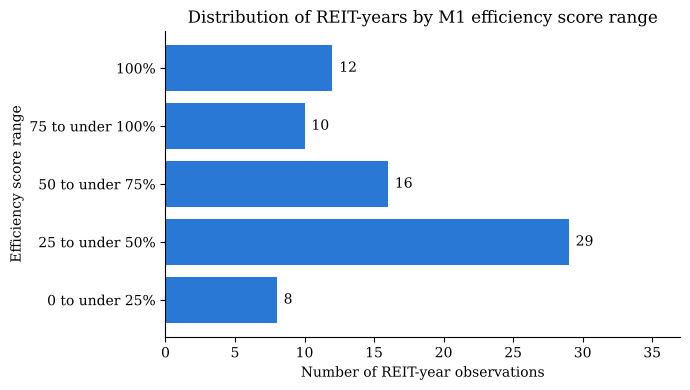

,Number of DMUs,Share (%)
M1,,
0 to under 25%,8,10.67
25 to under 50%,29,38.67
50 to under 75%,16,21.33
75 to under 100%,10,13.33
100%,12,16.00


[PASS] 4.1.1 | DMUs below 50%: reported 37, computed 37.0
[PASS] 4.1.1 | Share below 50% (%): reported 49.33, computed 49.3333
[PASS] 4.1.1 | DMUs at 75% or more: reported 22, computed 22.0
[PASS] 4.1.1 | Share at 75% or more (%): reported 29.33, computed 29.3333


In [22]:
bands1 = plot_bands(s1, "M1", "Figure_4_1_M1_score_bands.png")
display(bands1)
check("4.1.1", "DMUs below 50%", 37, bands1.iloc[:2, 0].sum(), 0)
check("4.1.1", "Share below 50% (%)", 49.33, 100 * bands1.iloc[:2, 0].sum() / 75)
check("4.1.1", "DMUs at 75% or more", 22, bands1.iloc[3:, 0].sum(), 0)
check("4.1.1", "Share at 75% or more (%)", 29.33, 100 * bands1.iloc[3:, 0].sum() / 75)

In [23]:
eff1 = efficient(s1)
check("4.1.1", "M1 efficient DMUs", ["P3", "P4", "P15", "P19", "P20", "P21", "P40", "P44", "P56", "P64", "P70", "P73"], eff1)
full_frontier = data.loc[eff1].groupby("Ticker").size()
print("REITs on the M1 frontier in all three years:", list(data.loc[eff1][data.loc[eff1, "Ticker"].isin(full_frontier[full_frontier == 3].index)]["REIT_name"].unique()))
check("4.1.1", "REITs efficient in every year", 1, int((full_frontier == 3).sum()), 0)

near = s1[s1 < EFF].sort_values(ascending=False).head(4)
bottom = s1.sort_values().head(3)
print("\nJust below the frontier:\n", near.to_string())
print("\nLowest scores:\n", bottom.to_string())
for d, v in {"P45": 93.67, "P57": 88.03, "P43": 87.06, "P7": 86.20}.items():
    check("4.1.1", f"{d} M1 score", v, s1[d])
check("4.1.1", "Four DMUs just below frontier", ["P45", "P57", "P43", "P7"], list(near.index))
for d, v in {"P26": 15.54, "P8": 18.34, "P27": 19.35}.items():
    check("4.1.1", f"{d} M1 score", v, s1[d])
check("4.1.1", "Three lowest DMUs", ["P26", "P8", "P27"], list(bottom.index))

[PASS] 4.1.1 | M1 efficient DMUs: reported P3, P4, P15, P19, P20, P21, P40, P44, P56, P64, P70, P73, computed P3, P4, P15, P19, P20, P21, P40, P44, P56, P64, P70, P73
REITs on the M1 frontier in all three years: ['Fair Value Reit-Ag']
[PASS] 4.1.1 | REITs efficient in every year: reported 1, computed 1.0

Just below the frontier:
 DMU
P45   93.67
P57   88.03
P43   87.06
P7    86.20

Lowest scores:
 DMU
P26   15.54
P8    18.34
P27   19.35
[PASS] 4.1.1 | P45 M1 score: reported 93.67, computed 93.67
[PASS] 4.1.1 | P57 M1 score: reported 88.03, computed 88.03
[PASS] 4.1.1 | P43 M1 score: reported 87.06, computed 87.06
[PASS] 4.1.1 | P7 M1 score: reported 86.2, computed 86.2
[PASS] 4.1.1 | Four DMUs just below frontier: reported P45, P57, P43, P7, computed P45, P57, P43, P7
[PASS] 4.1.1 | P26 M1 score: reported 15.54, computed 15.54
[PASS] 4.1.1 | P8 M1 score: reported 18.34, computed 18.34
[PASS] 4.1.1 | P27 M1 score: reported 19.35, computed 19.35
[PASS] 4.1.1 | Three lowest DMUs: reporte

### 6.2 Restricted CCR, M2 (Table 4.2)

In [24]:
s2 = scores["M2"]
t42 = summary_stats(s2)
print("Table 4.2. Summary of efficiency results under M2")
display(t42.to_frame("M2"))
for item, rep, key in [("Mean (%)", 49.93, "Mean"), ("Median (%)", 44.03, "Median"), ("Q1 (%)", 31.64, "Q1"),
                       ("Q3 (%)", 64.22, "Q3"), ("Min (%)", 15.54, "Min"), ("Efficient DMUs", 4, "Efficient DMUs"),
                       ("Share efficient (%)", 5.33, "Share efficient (%)")]:
    check("Table 4.2", item, rep, t42[key])
check("Table 4.2", "Spearman rho (M1, M2)", 0.949, rho(s1, s2), 0.0005)

eff2 = efficient(s2)
check("4.1.2", "M2 efficient DMUs", ["P4", "P21", "P56", "P70"], eff2)
check("4.1.2", "M2 frontier is a subset of M1 frontier", "True", str(set(eff2) <= set(eff1)))
diff12 = (s2 - s1).round(2)
check("4.1.2", "DMUs scoring higher under M2 than M1", 0, int((diff12 > 0).sum()), 0)
check("4.1.2", "DMUs scoring lower under M2 than M1", 50, int((diff12 < 0).sum()), 0)
check("4.1.2", "P19 M2 score", 98.07, s2["P19"])
check("4.1.2", "P20 M2 score", 97.52, s2["P20"])
check("4.1.2", "Lowest DMU under M2", "P26", s2.idxmin())

Table 4.2. Summary of efficiency results under M2


,M2
Observations,75.00
Mean,49.93
Median,44.03
Q1,31.64
Q3,64.22
IQR,32.58
Min,15.54
Max,100.00
Efficient DMUs,4.00
Share efficient (%),5.33


[PASS] Table 4.2 | Mean (%): reported 49.93, computed 49.9267
[PASS] Table 4.2 | Median (%): reported 44.03, computed 44.03
[PASS] Table 4.2 | Q1 (%): reported 31.64, computed 31.64
[PASS] Table 4.2 | Q3 (%): reported 64.22, computed 64.215
[PASS] Table 4.2 | Min (%): reported 15.54, computed 15.54
[PASS] Table 4.2 | Efficient DMUs: reported 4, computed 4.0
[PASS] Table 4.2 | Share efficient (%): reported 5.33, computed 5.3333
[PASS] Table 4.2 | Spearman rho (M1, M2): reported 0.949, computed 0.9492
[PASS] 4.1.2 | M2 efficient DMUs: reported P4, P21, P56, P70, computed P4, P21, P56, P70
[PASS] 4.1.2 | M2 frontier is a subset of M1 frontier: reported True, computed True
[PASS] 4.1.2 | DMUs scoring higher under M2 than M1: reported 0, computed 0.0
[PASS] 4.1.2 | DMUs scoring lower under M2 than M1: reported 50, computed 50.0
[PASS] 4.1.2 | P19 M2 score: reported 98.07, computed 98.07
[PASS] 4.1.2 | P20 M2 score: reported 97.52, computed 97.52
[PASS] 4.1.2 | Lowest DMU under M2: reported 

### 6.3 Efficiency by year (Table 4.3)

In [25]:
def year_table(s):
    g = s.groupby(data["Year"])
    return pd.DataFrame({"Median": g.median(),
                         "IQR (pp)": g.quantile(0.75) - g.quantile(0.25),
                         "Efficient DMUs": g.apply(lambda x: int((x >= EFF).sum()))})

t43 = pd.concat({"M1": year_table(s1), "M2": year_table(s2)}, axis=1)
print("Table 4.3. Classical DEA efficiency by year (n = 25 per year)")
display(t43)
reported_t43 = {("M1", 2022): (64.59, 39.50, 6), ("M1", 2023): (40.49, 32.47, 3), ("M1", 2024): (41.67, 37.46, 3),
                ("M2", 2022): (62.10, 30.87, 2), ("M2", 2023): (38.86, 26.12, 1), ("M2", 2024): (36.71, 26.38, 1)}
for (mdl, yr), (med, iqr, ne) in reported_t43.items():
    check("Table 4.3", f"{mdl} {yr} median", med, t43.loc[yr, (mdl, "Median")])
    check("Table 4.3", f"{mdl} {yr} IQR", iqr, t43.loc[yr, (mdl, "IQR (pp)")], 0.011)
    check("Table 4.3", f"{mdl} {yr} efficient", ne, t43.loc[yr, (mdl, "Efficient DMUs")], 0)

Table 4.3. Classical DEA efficiency by year (n = 25 per year)


M1                             M2                        
     Median IQR (pp) Efficient DMUs Median IQR (pp) Efficient DMUs
Year                                                              
2022  64.59    39.50              6  62.10    30.87              2
2023  40.49    32.47              3  38.86    26.12              1
2024  41.67    37.46              3  36.71    26.38              1

[PASS] Table 4.3 | M1 2022 median: reported 64.59, computed 64.59
[PASS] Table 4.3 | M1 2022 IQR: reported 39.5, computed 39.5
[PASS] Table 4.3 | M1 2022 efficient: reported 6, computed 6.0
[PASS] Table 4.3 | M1 2023 median: reported 40.49, computed 40.49
[PASS] Table 4.3 | M1 2023 IQR: reported 32.47, computed 32.47
[PASS] Table 4.3 | M1 2023 efficient: reported 3, computed 3.0
[PASS] Table 4.3 | M1 2024 median: reported 41.67, computed 41.67
[PASS] Table 4.3 | M1 2024 IQR: reported 37.46, computed 37.46
[PASS] Table 4.3 | M1 2024 efficient: reported 3, computed 3.0
[PASS] Table 4.3 | M2 2022 median: reported 62.1, computed 62.1
[PASS] Table 4.3 | M2 2022 IQR: reported 30.87, computed 30.87
[PASS] Table 4.3 | M2 2022 efficient: reported 2, computed 2.0
[PASS] Table 4.3 | M2 2023 median: reported 38.86, computed 38.86
[PASS] Table 4.3 | M2 2023 IQR: reported 26.12, computed 26.12
[PASS] Table 4.3 | M2 2023 efficient: reported 1, computed 1.0
[PASS] Table 4.3 | M2 2024 median: reported 

In [26]:
med_y = data.groupby("Year")[["IE", "TA", "IE_TA"]].median()
display(med_y)
check("4.1.3", "Median interest expense 2022 (US$m)", 31.4, med_y.loc[2022, "IE"], 0.05)
check("4.1.3", "Median interest expense 2024 (US$m)", 51.8, med_y.loc[2024, "IE"], 0.05)
check("4.1.3", "Rise in median interest expense 2022-24 (%)", 65, 100 * (med_y.loc[2024, "IE"] / med_y.loc[2022, "IE"] - 1), 0.5)
check("4.1.3", "Growth in median total assets 2022-24 (%)", 8, 100 * (med_y.loc[2024, "TA"] / med_y.loc[2022, "TA"] - 1), 0.5)

,IE,TA,IE_TA
Year,,,
2022,31.42,"3,215.90",0.82
2023,48.49,"3,396.86",1.27
2024,51.80,"3,476.40",1.35


[PASS] 4.1.3 | Median interest expense 2022 (US$m): reported 31.4, computed 31.416
[PASS] 4.1.3 | Median interest expense 2024 (US$m): reported 51.8, computed 51.8
[PASS] 4.1.3 | Rise in median interest expense 2022-24 (%): reported 65, computed 64.8841
[PASS] 4.1.3 | Growth in median total assets 2022-24 (%): reported 8, computed 8.1004


## 7. Geometric DEA Results (Sections 4.2 to 4.5)

### 7.1 M3 compared with M1 (Table 4.4 and Figure 4.2)

Table 4.4. Comparison of efficiency results under M1 and M3


,M1,M3
Median,51.94,98.71
Q1,32.28,88.75
Q3,79.72,100.00
IQR,47.44,11.25
Min,15.54,61.94
Efficient DMUs,12.00,35.00
Share efficient (%),16.00,46.67


[PASS] Table 4.4 | M3 Median (%): reported 98.71, computed 98.7116
[PASS] Table 4.4 | M3 Q1 (%): reported 88.75, computed 88.7513
[PASS] Table 4.4 | M3 Q3 (%): reported 100.0, computed 100.0
[PASS] Table 4.4 | M3 IQR (pp): reported 11.25, computed 11.2487
[PASS] Table 4.4 | M3 Min (%): reported 61.94, computed 61.9371
[PASS] Table 4.4 | M3 Efficient DMUs: reported 35, computed 35.0
[PASS] Table 4.4 | M3 Share efficient (%): reported 46.67, computed 46.6667
[PASS] Table 4.4 | M1 IQR (pp): reported 47.44, computed 47.435
[PASS] Table 4.4 | Spearman rho (M1, M3): reported 0.502, computed 0.5021
[PASS] 4.2.1 | All M1-efficient DMUs stay efficient in M3: reported True, computed True
[PASS] 4.2.1 | New DMUs joining the frontier in M3: reported 23, computed 23.0


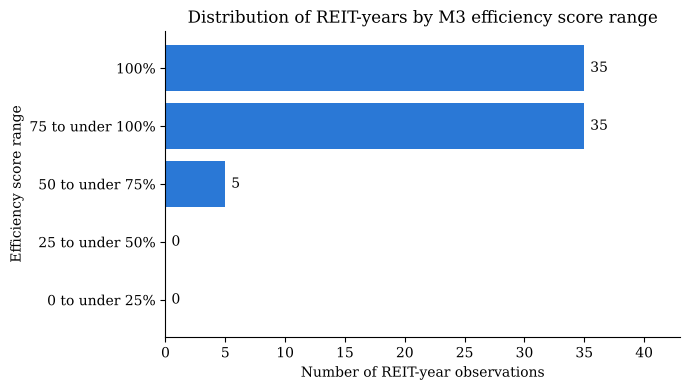

,Number of DMUs,Share (%)
M3,,
0 to under 25%,0,0.00
25 to under 50%,0,0.00
50 to under 75%,5,6.67
75 to under 100%,35,46.67
100%,35,46.67


In [27]:
s3 = scores["M3"]
t44 = pd.DataFrame({"M1": summary_stats(s1), "M3": summary_stats(s3)}).loc[["Median", "Q1", "Q3", "IQR", "Min", "Efficient DMUs", "Share efficient (%)"]]
print("Table 4.4. Comparison of efficiency results under M1 and M3")
display(t44)
for item, rep, key in [("Median (%)", 98.71, "Median"), ("Q1 (%)", 88.75, "Q1"), ("Q3 (%)", 100.00, "Q3"),
                       ("IQR (pp)", 11.25, "IQR"), ("Min (%)", 61.94, "Min"), ("Efficient DMUs", 35, "Efficient DMUs"),
                       ("Share efficient (%)", 46.67, "Share efficient (%)")]:
    check("Table 4.4", f"M3 {item}", rep, t44.loc[key, "M3"])
check("Table 4.4", "M1 IQR (pp)", 47.44, t44.loc["IQR", "M1"])
check("Table 4.4", "Spearman rho (M1, M3)", 0.502, rho(s1, s3), 0.0005)
eff3 = efficient(s3)
check("4.2.1", "All M1-efficient DMUs stay efficient in M3", "True", str(set(eff1) <= set(eff3)))
check("4.2.1", "New DMUs joining the frontier in M3", 23, len(set(eff3) - set(eff1)), 0)
display(plot_bands(s3, "M3", "M3_score_bands.png"))

In [28]:
r = ranks
check("4.2.1", "Tied rank of the 35 efficient DMUs in M3", 18, r.loc[eff3, "M3"].iloc[0], 0)
for d, v in {"P60": 71, "P36": 69, "P30": 63}.items():
    check("4.2.1", f"{d} M1 rank", v, r.loc[d, "M1"], 0)
    check("4.2.1", f"{d} efficient in M3", "True", str(s3[d] >= EFF))
for d, (a, b) in {"P38": (22, 61), "P13": (26, 64), "P7": (16, 51)}.items():
    check("4.2.1", f"{d} M1 rank", a, r.loc[d, "M1"], 0)
    check("4.2.1", f"{d} M3 rank", b, r.loc[d, "M3"], 0)
check("4.2.1", "P38 M1 score", 76.67, s1["P38"])
check("4.2.1", "P38 M3 score", 86.87, s3["P38"])
check("4.2.1", "P7 M3 score", 93.30, s3["P7"])

W3 = software_w["M3"]
cost3 = W3[["Inv_IE", "Inv_OE"]].sum(axis=1)
check("4.2.1", "M3 average cost weight (%)", 11.0, 100 * cost3.mean(), 0.05)
check("4.2.1", "M3 DMUs with cost weight below 1%", 18, int((cost3 < 0.01).sum()), 0)
check("4.2.1", "M3 average ESG weight (%)", 78.7, shares.loc["M3", "ESG (ES, SS, GS)"], 0.05)
check("4.2.1", "M3 average financial weight (%)", 10.3, shares.loc["M3", "Financial (R, TA)"], 0.05)

[PASS] 4.2.1 | Tied rank of the 35 efficient DMUs in M3: reported 18, computed 18.0
[PASS] 4.2.1 | P60 M1 rank: reported 71, computed 71.0
[PASS] 4.2.1 | P60 efficient in M3: reported True, computed True
[PASS] 4.2.1 | P36 M1 rank: reported 69, computed 69.0
[PASS] 4.2.1 | P36 efficient in M3: reported True, computed True
[PASS] 4.2.1 | P30 M1 rank: reported 63, computed 63.0
[PASS] 4.2.1 | P30 efficient in M3: reported True, computed True
[PASS] 4.2.1 | P38 M1 rank: reported 22, computed 22.0
[PASS] 4.2.1 | P38 M3 rank: reported 61, computed 61.0
[PASS] 4.2.1 | P13 M1 rank: reported 26, computed 26.0
[PASS] 4.2.1 | P13 M3 rank: reported 64, computed 64.0
[PASS] 4.2.1 | P7 M1 rank: reported 16, computed 16.0
[PASS] 4.2.1 | P7 M3 rank: reported 51, computed 51.0
[PASS] 4.2.1 | P38 M1 score: reported 76.67, computed 76.67
[PASS] 4.2.1 | P38 M3 score: reported 86.87, computed 86.8657
[PASS] 4.2.1 | P7 M3 score: reported 93.3, computed 93.295
[PASS] 4.2.1 | M3 average cost weight (%): repo

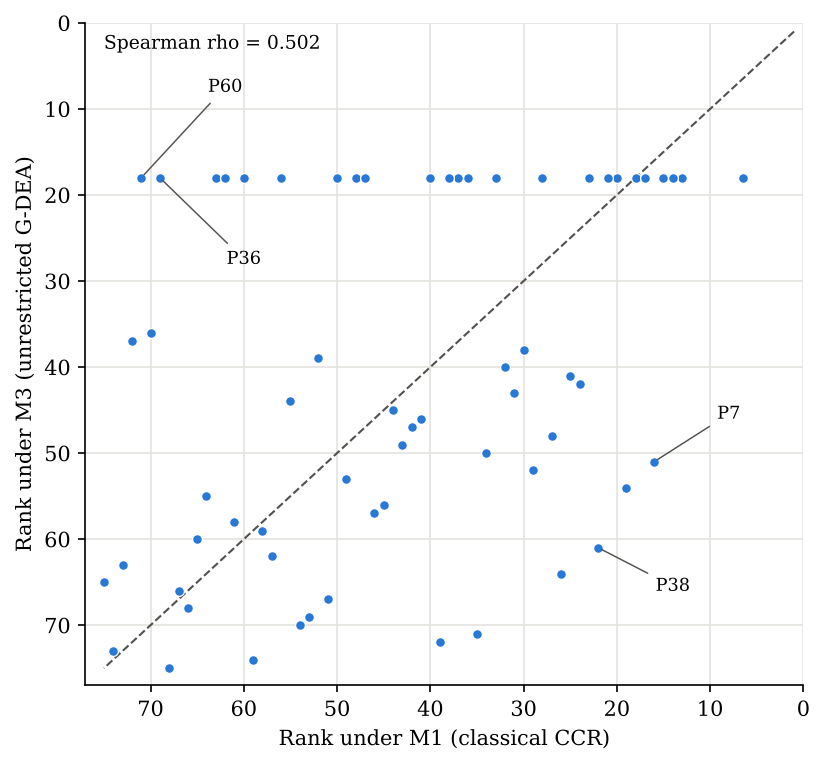

In [29]:
LABELS = {"P60": (62, 8), "P36": (60, 28), "P38": (14, 66), "P7": (8, 46)}
n = len(scores)
fig, ax = plt.subplots(figsize=(5.6, 5.2), dpi=150)
ax.plot([1, n], [1, n], ls="--", color="#52514e", lw=1, label="Equal rank under both models")
ax.scatter(r["M1"], r["M3"], s=22, color="#2a78d6", edgecolor="white", lw=0.6, zorder=3)
for dmu, pos in LABELS.items():
    ax.annotate(dmu, (r.loc[dmu, "M1"], r.loc[dmu, "M3"]), xytext=pos, fontsize=8.5, ha="center",
                arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.7))
ax.set_xlabel("Rank under M1 (classical CCR)")
ax.set_ylabel("Rank under M3 (unrestricted G-DEA)")
ax.set_xlim(0, n + 2)
ax.set_ylim(0, n + 2)
ax.invert_xaxis()
ax.invert_yaxis()
ax.text(n, 3, f"Spearman rho = {rho(s1, s3):.3f}", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, color="#e4e3df", lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "Figure_4_2_rank_M1_M3.png", dpi=300)
plt.show()

### 7.2 Separating aggregation from weight flexibility, GE (Table 4.5)

In [30]:
sge = scores["GE"]
t45 = pd.DataFrame({mdl: [scores[mdl].median(), summary_stats(scores[mdl])["IQR"],
                          int((scores[mdl] >= EFF).sum()), rho(s1, scores[mdl])]
                    for mdl in ["M1", "GE", "M3"]},
                   index=["Median (%)", "IQR (pp)", "Efficient DMUs", "rho with M1"]).T
print("Table 4.5. Effect of aggregation and of category-weight flexibility")
display(t45)
check("Table 4.5", "GE median (%)", 50.54, t45.loc["GE", "Median (%)"])
check("Table 4.5", "GE IQR (pp)", 45.36, t45.loc["GE", "IQR (pp)"], 0.011)
check("Table 4.5", "GE efficient DMUs", 10, t45.loc["GE", "Efficient DMUs"], 0)
check("Table 4.5", "Spearman rho (M1, GE)", 0.993, t45.loc["GE", "rho with M1"], 0.0005)
check("4.2.2", "Spearman rho (GE, M3)", 0.538, rho(sge, s3), 0.0005)
effge = efficient(sge)
check("4.2.2", "M1-efficient DMUs that stay efficient in GE", 10, len(set(eff1) & set(effge)), 0)
check("4.2.2", "M1-efficient DMUs that leave the frontier in GE", ["P40", "P73"], sorted(set(eff1) - set(effge)))
check("4.2.2", "P40 GE score", 98.31, sge["P40"])
check("4.2.2", "P73 GE score", 95.08, sge["P73"])

Table 4.5. Effect of aggregation and of category-weight flexibility


,Median (%),IQR (pp),Efficient DMUs,rho with M1
M1,51.94,47.44,12.00,1.00
GE,50.54,45.36,10.00,0.99
M3,98.71,11.25,35.00,0.50


[PASS] Table 4.5 | GE median (%): reported 50.54, computed 50.54
[PASS] Table 4.5 | GE IQR (pp): reported 45.36, computed 45.36
[PASS] Table 4.5 | GE efficient DMUs: reported 10, computed 10.0
[PASS] Table 4.5 | Spearman rho (M1, GE): reported 0.993, computed 0.9931
[PASS] 4.2.2 | Spearman rho (GE, M3): reported 0.538, computed 0.5382
[PASS] 4.2.2 | M1-efficient DMUs that stay efficient in GE: reported 10, computed 10.0
[PASS] 4.2.2 | M1-efficient DMUs that leave the frontier in GE: reported P40, P73, computed P40, P73
[PASS] 4.2.2 | P40 GE score: reported 98.31, computed 98.31
[PASS] 4.2.2 | P73 GE score: reported 95.08, computed 95.08


### 7.3 M4 compared with M2 (Table 4.6)

Table 4.6. Comparison of efficiency results under M2 and M4


,M2,M4
Median,44.03,94.14
IQR,32.58,15.10
Efficient DMUs,4.00,23.00
Share efficient (%),5.33,30.67


[PASS] Table 4.6 | M2 IQR (pp): reported 32.58, computed 32.575
[PASS] Table 4.6 | M4 median (%): reported 94.14, computed 94.1422
[PASS] Table 4.6 | M4 IQR (pp): reported 15.1, computed 15.0952
[PASS] Table 4.6 | M4 efficient DMUs: reported 23, computed 23.0
[PASS] Table 4.6 | M4 share efficient (%): reported 30.67, computed 30.6667
[PASS] Table 4.6 | Spearman rho (M2, M4): reported 0.644, computed 0.644
[PASS] 4.2.3 | All M2-efficient DMUs stay efficient in M4: reported True, computed True
[PASS] 4.2.3 | New DMUs joining the frontier in M4: reported 19, computed 19.0
[PASS] 4.2.3 | P60 M2 rank: reported 71, computed 71.0
[PASS] 4.2.3 | P60 efficient in M4: reported True, computed True
[PASS] 4.2.3 | P58 M2 rank: reported 61, computed 61.0
[PASS] 4.2.3 | P58 efficient in M4: reported True, computed True
[PASS] 4.2.3 | P50 M2 rank: reported 50, computed 50.0
[PASS] 4.2.3 | P50 efficient in M4: reported True, computed True
[PASS] 4.2.3 | P38 M2 rank: reported 18, computed 18.0
[PASS] 4.

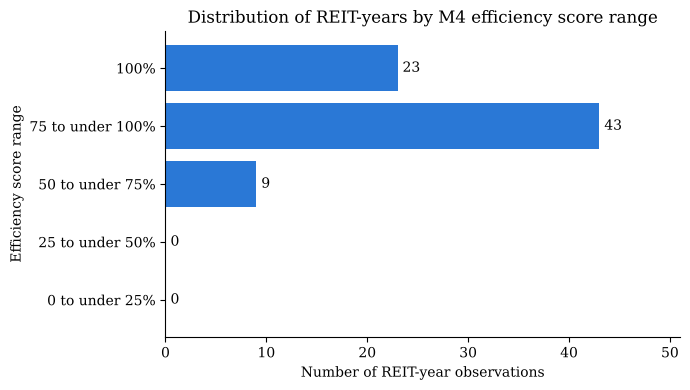

,Number of DMUs,Share (%)
M4,,
0 to under 25%,0,0.00
25 to under 50%,0,0.00
50 to under 75%,9,12.00
75 to under 100%,43,57.33
100%,23,30.67


In [31]:
s4 = scores["M4"]
t46 = pd.DataFrame({"M2": summary_stats(s2), "M4": summary_stats(s4)}).loc[["Median", "IQR", "Efficient DMUs", "Share efficient (%)"]]
print("Table 4.6. Comparison of efficiency results under M2 and M4")
display(t46)
check("Table 4.6", "M2 IQR (pp)", 32.58, t46.loc["IQR", "M2"])
check("Table 4.6", "M4 median (%)", 94.14, t46.loc["Median", "M4"])
check("Table 4.6", "M4 IQR (pp)", 15.10, t46.loc["IQR", "M4"])
check("Table 4.6", "M4 efficient DMUs", 23, t46.loc["Efficient DMUs", "M4"], 0)
check("Table 4.6", "M4 share efficient (%)", 30.67, t46.loc["Share efficient (%)", "M4"])
check("Table 4.6", "Spearman rho (M2, M4)", 0.644, rho(s2, s4), 0.0005)
eff4 = efficient(s4)
check("4.2.3", "All M2-efficient DMUs stay efficient in M4", "True", str(set(eff2) <= set(eff4)))
check("4.2.3", "New DMUs joining the frontier in M4", 19, len(set(eff4) - set(eff2)), 0)
for d, a in {"P60": 71, "P58": 61, "P50": 50}.items():
    check("4.2.3", f"{d} M2 rank", a, r.loc[d, "M2"], 0)
    check("4.2.3", f"{d} efficient in M4", "True", str(s4[d] >= EFF))
for d, (a, b) in {"P38": (18, 55), "P39": (28, 67), "P7": (9, 42)}.items():
    check("4.2.3", f"{d} M2 rank", a, r.loc[d, "M2"], 0)
    check("4.2.3", f"{d} M4 rank", b, r.loc[d, "M4"], 0)

W4 = software_w["M4"]
cost4 = W4[["Inv_IE", "Inv_OE"]].sum(axis=1)
check("4.2.3", "M4 DMUs with cost weight at the 20% lower limit", 67, int(np.isclose(cost4, 0.2, atol=1e-4).sum()), 0)
check("4.2.3", "M4 average ESG weight (%)", 61.2, shares.loc["M4", "ESG (ES, SS, GS)"], 0.05)
check("4.2.3", "M4 average financial weight (%)", 16.4, shares.loc["M4", "Financial (R, TA)"], 0.05)
display(plot_bands(s4, "M4", "M4_score_bands.png"))

### 7.4 M5 compared with M3 (Table 4.7)

In [32]:
s5 = scores["M5"]
t47 = pd.DataFrame({"M3": summary_stats(s3), "M5": summary_stats(s5)}).loc[["Median", "IQR", "Efficient DMUs", "Share efficient (%)"]]
print("Table 4.7. Comparison of efficiency results under M3 and M5")
display(t47)
check("Table 4.7", "M5 median (%)", 98.71, t47.loc["Median", "M5"])
check("Table 4.7", "M5 IQR (pp)", 11.25, t47.loc["IQR", "M5"])
check("Table 4.7", "M5 efficient DMUs", 35, t47.loc["Efficient DMUs", "M5"], 0)
check("Table 4.7", "Spearman rho (M3, M5)", 1.000, rho(s3, s5), 0.0005)
check("4.3.1", "Same frontier in M3 and M5", "True", str(efficient(s3) == efficient(s5)))
check("4.3.1", "Largest |M5 - M3| (pp), about 0.01", 0.01, (s5 - s3).abs().max(), 0.005)

Table 4.7. Comparison of efficiency results under M3 and M5


,M3,M5
Median,98.71,98.71
IQR,11.25,11.25
Efficient DMUs,35.00,35.00
Share efficient (%),46.67,46.67


[PASS] Table 4.7 | M5 median (%): reported 98.71, computed 98.7116
[PASS] Table 4.7 | M5 IQR (pp): reported 11.25, computed 11.2487
[PASS] Table 4.7 | M5 efficient DMUs: reported 35, computed 35.0
[PASS] Table 4.7 | Spearman rho (M3, M5): reported 1.0, computed 1.0
[PASS] 4.3.1 | Same frontier in M3 and M5: reported True, computed True
[PASS] 4.3.1 | Largest |M5 - M3| (pp), about 0.01: reported 0.01, computed 0.0111


### 7.5 M6 compared with M5 (Table 4.8)

Table 4.8. Comparison of efficiency results under M5 and M6


,M5,M6
Mean,93.47,82.64
Median,98.71,86.23
IQR,11.25,27.07
Min,61.94,49.78
Efficient DMUs,35.00,16.00
Share efficient (%),46.67,21.33


[PASS] Table 4.8 | M6 Mean (%): reported 82.64, computed 82.6387
[PASS] Table 4.8 | M6 Median (%): reported 86.23, computed 86.2323
[PASS] Table 4.8 | M6 IQR (pp): reported 27.07, computed 27.0728
[PASS] Table 4.8 | M6 Min (%): reported 49.78, computed 49.7769
[PASS] Table 4.8 | M6 Efficient DMUs: reported 16, computed 16.0
[PASS] Table 4.8 | M6 Share efficient (%): reported 21.33, computed 21.3333
[PASS] Table 4.8 | M5 mean (%): reported 93.47, computed 93.4678
[PASS] Table 4.8 | Spearman rho (M5, M6): reported 0.731, computed 0.7312
[PASS] 4.3.2 | DMUs scoring higher under M6 than M5: reported 0, computed 0.0
[PASS] 4.3.2 | Non-efficient M6 DMUs that score lower than in M5: reported 59, computed 59.0
[PASS] 4.3.2 | M5-efficient DMUs dropping off in M6: reported 19, computed 19.0
[PASS] 4.3.2 | DMUs joining the frontier in M6: reported 0, computed 0.0
[PASS] 4.3.2 | M6 efficient DMUs: reported P3, P4, P15, P19, P20, P21, P28, P31, P44, P55, P56, P57, P58, P60, P64, P70, computed P3, P

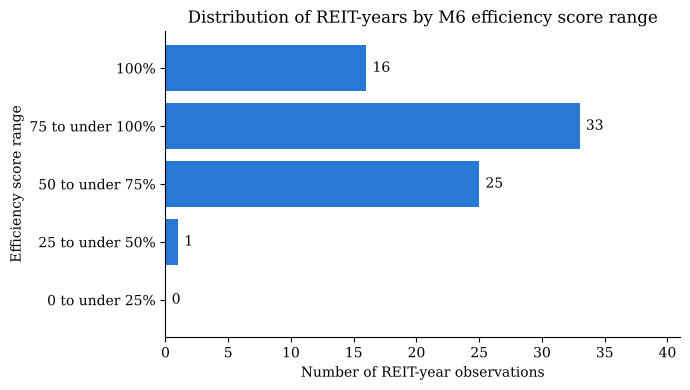

,Number of DMUs,Share (%)
M6,,
0 to under 25%,0,0.00
25 to under 50%,1,1.33
50 to under 75%,25,33.33
75 to under 100%,33,44.00
100%,16,21.33


In [33]:
s6 = scores["M6"]
t48 = pd.DataFrame({"M5": summary_stats(s5), "M6": summary_stats(s6)}).loc[["Mean", "Median", "IQR", "Min", "Efficient DMUs", "Share efficient (%)"]]
print("Table 4.8. Comparison of efficiency results under M5 and M6")
display(t48)
for item, rep, key in [("Mean (%)", 82.64, "Mean"), ("Median (%)", 86.23, "Median"), ("IQR (pp)", 27.07, "IQR"),
                       ("Min (%)", 49.78, "Min"), ("Efficient DMUs", 16, "Efficient DMUs"),
                       ("Share efficient (%)", 21.33, "Share efficient (%)")]:
    check("Table 4.8", f"M6 {item}", rep, t48.loc[key, "M6"])
check("Table 4.8", "M5 mean (%)", 93.47, t48.loc["Mean", "M5"])
check("Table 4.8", "Spearman rho (M5, M6)", 0.731, rho(s5, s6), 0.0005)

d56 = (s6 - s5).round(2)
eff5, eff6 = efficient(s5), efficient(s6)
check("4.3.2", "DMUs scoring higher under M6 than M5", 0, int((d56 > 0).sum()), 0)
check("4.3.2", "Non-efficient M6 DMUs that score lower than in M5", 59, int(((d56 < 0) & (s6 < EFF)).sum()), 0)
check("4.3.2", "M5-efficient DMUs dropping off in M6", 19, len(set(eff5) - set(eff6)), 0)
check("4.3.2", "DMUs joining the frontier in M6", 0, len(set(eff6) - set(eff5)), 0)
check("4.3.2", "M6 efficient DMUs", ["P3", "P4", "P15", "P19", "P20", "P21", "P28", "P31", "P44", "P55",
                                      "P56", "P57", "P58", "P60", "P64", "P70"], eff6)
falls = (s5 - s6).sort_values(ascending=False)
print("Largest falls from M5 to M6:\n", falls.head(3).round(2).to_string())
check("4.3.2", "Largest fall: P36 (pp)", 40.89, falls["P36"])
check("4.3.2", "Second largest fall: P34 (pp)", 37.87, falls["P34"])
check("4.3.2", "Two largest falls", ["P36", "P34"], list(falls.index[:2]))
check("4.3.2", "P36 M6 rank", 71, r.loc["P36", "M6"], 0)
check("4.3.2", "P38 M5 rank", 61, r.loc["P38", "M5"], 0)
check("4.3.2", "P38 M6 rank", 38, r.loc["P38", "M6"], 0)
check("4.3.2", "P38 M5 score", 86.86, s5["P38"])
check("4.3.2", "P38 M6 score", 86.23, s6["P38"])
check("4.3.2", "M6 average cost weight (%)", 33.3, shares.loc["M6", "Resource-Cost"], 0.05)
check("4.3.2", "M6 average financial weight (%)", 37.6, shares.loc["M6", "Financial (R, TA)"], 0.05)
check("4.3.2", "M6 average ESG weight (%)", 29.2, shares.loc["M6", "ESG (ES, SS, GS)"], 0.05)
display(plot_bands(s6, "M6", "M6_score_bands.png"))

### 7.6 Combined effect of the extension (Section 4.4 and Table 4.9)

In [34]:
traj = pd.DataFrame({
    "M1": r["M1"], "GE": r["GE"],
    "M3 and M5": np.where(s3 >= EFF, "100%", "Rank " + r["M3"].map("{:g}".format)),
    "M6": np.where(s6 >= EFF, "100%", "Rank " + r["M6"].map("{:g}".format)),
}, index=scores.index).loc[["P58", "P60", "P36", "P38", "P7"]]
print("Table 4.9. Selected trajectories across the models (ranks; 100% = efficient)")
display(traj)
reported_t49 = {"P58": (62, 64, "100%", "100%"), "P60": (71, 71, "100%", "100%"),
                "P36": (69, 65, "100%", "Rank 71"), "P38": (22, 23, "Rank 61", "Rank 38"),
                "P7": (16, 17, "Rank 51", "Rank 35")}
for d, (a, b, c, e) in reported_t49.items():
    check("Table 4.9", f"{d} M1 rank", a, traj.loc[d, "M1"], 0)
    check("Table 4.9", f"{d} GE rank", b, traj.loc[d, "GE"], 0)
    check("Table 4.9", f"{d} M3/M5", c, traj.loc[d, "M3 and M5"])
    check("Table 4.9", f"{d} M6", e, traj.loc[d, "M6"])

Table 4.9. Selected trajectories across the models (ranks; 100% = efficient)


,M1,GE,M3 and M5,M6
DMU,,,,
P58,62.00,64.00,100%,100%
P60,71.00,71.00,100%,100%
P36,69.00,65.00,100%,Rank 71
P38,22.00,23.00,Rank 61,Rank 38
P7,16.00,17.00,Rank 51,Rank 35


[PASS] Table 4.9 | P58 M1 rank: reported 62, computed 62.0
[PASS] Table 4.9 | P58 GE rank: reported 64, computed 64.0
[PASS] Table 4.9 | P58 M3/M5: reported 100%, computed 100%
[PASS] Table 4.9 | P58 M6: reported 100%, computed 100%
[PASS] Table 4.9 | P60 M1 rank: reported 71, computed 71.0
[PASS] Table 4.9 | P60 GE rank: reported 71, computed 71.0
[PASS] Table 4.9 | P60 M3/M5: reported 100%, computed 100%
[PASS] Table 4.9 | P60 M6: reported 100%, computed 100%
[PASS] Table 4.9 | P36 M1 rank: reported 69, computed 69.0
[PASS] Table 4.9 | P36 GE rank: reported 65, computed 65.0
[PASS] Table 4.9 | P36 M3/M5: reported 100%, computed 100%
[PASS] Table 4.9 | P36 M6: reported Rank 71, computed Rank 71
[PASS] Table 4.9 | P38 M1 rank: reported 22, computed 22.0
[PASS] Table 4.9 | P38 GE rank: reported 23, computed 23.0
[PASS] Table 4.9 | P38 M3/M5: reported Rank 61, computed Rank 61
[PASS] Table 4.9 | P38 M6: reported Rank 38, computed Rank 38
[PASS] Table 4.9 | P7 M1 rank: reported 16, comput

In [35]:
y6 = year_table(s6)
display(y6)
check("4.4", "M6 median 2022 (%)", 95.02, y6.loc[2022, "Median"])
check("4.4", "M6 median 2023 (%)", 76.64, y6.loc[2023, "Median"])
check("4.4", "M6 median 2024 (%)", 82.22, y6.loc[2024, "Median"])
check("4.4", "M6 efficient DMUs from 2022", 8, y6.loc[2022, "Efficient DMUs"], 0)

check("4.4", "Spearman rho (M1, M6)", 0.729, rho(s1, s6), 0.0005)
check("4.4", "M1-efficient DMUs still efficient in M6", 10, len(set(eff1) & set(eff6)), 0)
check("4.4", "M1-efficient DMUs not efficient in M6", ["P40", "P73"], sorted(set(eff1) - set(eff6)))
check("4.4", "P40 M6 score", 99.54, s6["P40"])
check("4.4", "P73 M6 score", 98.04, s6["P73"])
check("4.4", "New frontier DMUs in M6 (vs M1)", ["P28", "P31", "P55", "P57", "P58", "P60"], sorted(set(eff6) - set(eff1)))
all_models = sorted(set.intersection(*[set(efficient(scores[m])) for m in MODELS]), key=lambda d: int(d[1:]))
check("4.4", "Efficient under every model incl. GE", ["P4", "P21", "P56", "P70"], all_models)

,Median,IQR (pp),Efficient DMUs
Year,,,
2022,95.02,22.08,8
2023,76.64,19.62,3
2024,82.22,24.34,5


[PASS] 4.4 | M6 median 2022 (%): reported 95.02, computed 95.0197
[PASS] 4.4 | M6 median 2023 (%): reported 76.64, computed 76.6414
[PASS] 4.4 | M6 median 2024 (%): reported 82.22, computed 82.2207
[PASS] 4.4 | M6 efficient DMUs from 2022: reported 8, computed 8.0
[PASS] 4.4 | Spearman rho (M1, M6): reported 0.729, computed 0.729
[PASS] 4.4 | M1-efficient DMUs still efficient in M6: reported 10, computed 10.0
[PASS] 4.4 | M1-efficient DMUs not efficient in M6: reported P40, P73, computed P40, P73
[PASS] 4.4 | P40 M6 score: reported 99.54, computed 99.5414
[PASS] 4.4 | P73 M6 score: reported 98.04, computed 98.0427
[PASS] 4.4 | New frontier DMUs in M6 (vs M1): reported P28, P31, P55, P57, P58, P60, computed P28, P31, P55, P57, P58, P60
[PASS] 4.4 | Efficient under every model incl. GE: reported P4, P21, P56, P70, computed P4, P21, P56, P70


## 8. Supporting Analysis for the Discussion (Chapter V)

Cost ratios: interest expense over total assets (IE/TA) and operating expenses over revenue (OE/R), both in %.

### 8.1 What the classical benchmark reveals (Section 5.1)

In [36]:
check("5.1", "Output expansion needed by the median DMU (%), roughly 90", 90, 100 * (100 / s1.median() - 1), 5)
check("5.1", "rho(M1, IE/TA)", -0.54, rho(s1, data["IE_TA"]), 0.005)
check("5.1", "rho(M1, OE/R)", -0.63, rho(s1, data["OE_R"]), 0.005)
check("5.1", "rho(M2, IE/TA)", -0.72, rho(s2, data["IE_TA"]), 0.005)
check("5.1", "rho(M2, OE/R)", -0.50, rho(s2, data["OE_R"]), 0.005)

stable = ["P4", "P21", "P56", "P70"]
display(data.loc[stable, ["REIT_name", "Year", "IE_TA", "OE_R"]])
check("5.1", "Lowest IE/TA among the stable four (%)", 0.28, data.loc[stable, "IE_TA"].min(), 0.005)
check("5.1", "Highest IE/TA among the stable four (%)", 0.52, data.loc[stable, "IE_TA"].max(), 0.005)
check("5.1", "Median IE/TA, full sample (%)", 1.19, data["IE_TA"].median(), 0.005)
print("Stable four OE/R vs sample median:", data.loc[stable, "OE_R"].round(1).to_dict(), round(data["OE_R"].median(), 1))
check("5.1", "IGD 2023 (P26) IE/TA (%)", 2.5, data.loc["P26", "IE_TA"], 0.05)
check("5.1", "IGD 2024 (P27) IE/TA (%)", 3.7, data.loc["P27", "IE_TA"], 0.05)

[PASS] 5.1 | Output expansion needed by the median DMU (%), roughly 90: reported 90, computed 92.5298
[PASS] 5.1 | rho(M1, IE/TA): reported -0.54, computed -0.541
[PASS] 5.1 | rho(M1, OE/R): reported -0.63, computed -0.6286
[PASS] 5.1 | rho(M2, IE/TA): reported -0.72, computed -0.7202
[PASS] 5.1 | rho(M2, OE/R): reported -0.5, computed -0.5013


,REIT_name,Year,IE_TA,OE_R
DMU,,,,
P4,Altarea,2022,0.52,7.25
P21,Fair Value Reit-Ag,2024,0.44,45.74
P56,Shurgard Self Storage Ltd,2023,0.41,10.16
P70,Xior Student Housing Nv,2022,0.28,45.14


[PASS] 5.1 | Lowest IE/TA among the stable four (%): reported 0.28, computed 0.2808
[PASS] 5.1 | Highest IE/TA among the stable four (%): reported 0.52, computed 0.5216
[PASS] 5.1 | Median IE/TA, full sample (%): reported 1.19, computed 1.1937
Stable four OE/R vs sample median: {'P4': 7.2, 'P21': 45.7, 'P56': 10.2, 'P70': 45.1} 35.9
[CHECK] 5.1 | IGD 2023 (P26) IE/TA (%): reported 2.5, computed 2.4481
[PASS] 5.1 | IGD 2024 (P27) IE/TA (%): reported 3.7, computed 3.6949


In [37]:
check("5.1", "M1 median 2022 (%)", 64.59, s1[data["Year"] == 2022].median())
check("5.1", "M1 median 2023 (%)", 40.49, s1[data["Year"] == 2023].median())
check("5.1", "Median IE/TA 2022 (%)", 0.82, med_y.loc[2022, "IE_TA"], 0.005)
check("5.1", "Median IE/TA 2024 (%)", 1.35, med_y.loc[2024, "IE_TA"], 0.005)

# Peers come from the envelopment solution (lambda > 0). Peer sets can be non-unique at degenerate optima.
ineff = s1 < EFF
peer_links = pd.DataFrame(LAMBDA > 1e-6, index=data.index, columns=data.index).loc[ineff]
peer_count = peer_links.sum().sort_values(ascending=False)
print("Number of inefficient DMUs referencing each peer under M1:")
display(peer_count[peer_count > 0].to_frame("Times used as peer").join(data[["REIT_name", "Year"]]))
check("5.1", "Inefficient DMUs under M1", 63, int(ineff.sum()), 0)
check("5.1", "Most used peer", "P56", peer_count.index[0])
check("5.1", "Inefficient DMUs referencing Shurgard 2023 (P56)", 47, peer_count["P56"], 0)
share_2022 = peer_links.loc[:, data["Year"] == 2022].values.sum() / peer_links.values.sum()
check("5.1", "Share of peer links supplied by 2022 DMUs (%)", 39, 100 * share_2022, 0.5)

[PASS] 5.1 | M1 median 2022 (%): reported 64.59, computed 64.59
[PASS] 5.1 | M1 median 2023 (%): reported 40.49, computed 40.49
[PASS] 5.1 | Median IE/TA 2022 (%): reported 0.82, computed 0.8161
[PASS] 5.1 | Median IE/TA 2024 (%): reported 1.35, computed 1.3501
Number of inefficient DMUs referencing each peer under M1:


,Times used as peer,REIT_name,Year
DMU,,,
P56,47,Shurgard Self Storage Ltd,2023
P70,30,Xior Student Housing Nv,2022
P4,30,Altarea,2022
P21,25,Fair Value Reit-Ag,2024
P3,23,Aedifica,2024
P44,20,Newriver Reit Plc,2023
P40,10,Nextensa,2022
P73,6,Castellana Properties Socimi,2022
P20,4,Fair Value Reit-Ag,2023


[PASS] 5.1 | Inefficient DMUs under M1: reported 63, computed 63.0
[PASS] 5.1 | Most used peer: reported P56, computed P56
[PASS] 5.1 | Inefficient DMUs referencing Shurgard 2023 (P56): reported 47, computed 47.0
[PASS] 5.1 | Share of peer links supplied by 2022 DMUs (%): reported 39, computed 38.5787


In [38]:
check("5.1", "rho(M1, ES)", 0.03, rho(s1, data["ES"]), 0.005)
check("5.1", "rho(M1, SS)", -0.25, rho(s1, data["SS"]), 0.005)

# Appendix D: M1 re-estimated without the three ESG outputs (rounded to 2 decimals, as PIM-DEA reports)
m1_noesg = pd.Series(ccr_output_multiplier(X, data[["TA", "R"]].values)[0], index=data.index).round(2)
esg_gain = s1 - m1_noesg
appendix_d = data[["REIT_name", "Year"]].assign(M1=s1, M1_without_ESG=m1_noesg, Gain_from_ESG=esg_gain)
appendix_d.to_excel(OUT_DIR / "Appendix_D_M1_without_ESG.xlsx")
display(appendix_d.sort_values("Gain_from_ESG", ascending=False).head(10))

print(f"Median gain = {esg_gain.median():.2f} points; below 1 point: {(esg_gain < 1).sum()}, 1 point or less: {(esg_gain <= 1).sum()} of 75")
check("5.1", "DMUs gaining 1 point or less from ESG (about half of 75)", 37.5, int((esg_gain <= 1).sum()), 1)
check("5.1", "rho(M1, M1 without ESG)", 0.95, rho(s1, m1_noesg), 0.005)
only_esg = sorted(set(eff1) - set(efficient(m1_noesg)), key=lambda d: int(d[1:]))
print("Frontier positions that exist only because ESG is included:", only_esg)
check("5.1", "Frontier positions due only to ESG", 7, len(only_esg), 0)
check("5.1", "rho(gain from ESG, total assets)", -0.89, rho(esg_gain, data["TA"]), 0.005)
fvi = ["P19", "P20", "P21"]
check("5.1", "Fair Value REIT smallest ESG gain (pp)", 20, esg_gain[fvi].min(), 0.5)
check("5.1", "Fair Value REIT largest ESG gain (pp)", 27, esg_gain[fvi].max(), 0.5)
below_med = (data.loc[fvi, ["ES", "SS", "GS"]] < data[["ES", "SS", "GS"]].median()).all().all()
check("5.1", "Fair Value REIT below median on all three pillars", "True", str(below_med))

[PASS] 5.1 | rho(M1, ES): reported 0.03, computed 0.028
[PASS] 5.1 | rho(M1, SS): reported -0.25, computed -0.2503


,REIT_name,Year,M1,M1_without_ESG,Gain_from_ESG
DMU,,,,,
P73,Castellana Properties Socimi,2022,100.00,56.53,43.47
P45,Newriver Reit Plc,2024,93.67,51.57,42.10
P21,Fair Value Reit-Ag,2024,100.00,72.74,27.26
P74,Castellana Properties Socimi,2023,55.37,31.94,23.43
P41,Nextensa,2023,61.43,39.94,21.49
P20,Fair Value Reit-Ag,2023,100.00,78.76,21.24
P19,Fair Value Reit-Ag,2022,100.00,79.66,20.34
P40,Nextensa,2022,100.00,79.91,20.09
P44,Newriver Reit Plc,2023,100.00,79.94,20.06


Median gain = 1.00 points; below 1 point: 37, 1 point or less: 38 of 75
[PASS] 5.1 | DMUs gaining 1 point or less from ESG (about half of 75): reported 37.5, computed 38.0
[CHECK] 5.1 | rho(M1, M1 without ESG): reported 0.95, computed 0.9571
Frontier positions that exist only because ESG is included: ['P19', 'P20', 'P21', 'P40', 'P44', 'P64', 'P73']
[PASS] 5.1 | Frontier positions due only to ESG: reported 7, computed 7.0
[PASS] 5.1 | rho(gain from ESG, total assets): reported -0.89, computed -0.8874
[PASS] 5.1 | Fair Value REIT smallest ESG gain (pp): reported 20, computed 20.34
[PASS] 5.1 | Fair Value REIT largest ESG gain (pp): reported 27, computed 27.26
[PASS] 5.1 | Fair Value REIT below median on all three pillars: reported True, computed True


In [39]:
urw = data.index[data["Ticker"] == "URW FP Equity"]
print("URW M1 ranks:", r.loc[urw, "M1"].to_dict())
check("5.1", "URW best M1 rank", 62, r.loc[urw, "M1"].min(), 0)
check("5.1", "URW worst M1 rank", 72, r.loc[urw, "M1"].max(), 0)
check("5.1", "rho(M1, TA)", -0.21, rho(s1, data["TA"]), 0.005)
check("5.1", "rho(M1 without ESG, TA)", 0.00, rho(m1_noesg, data["TA"]), 0.005)

URW M1 ranks: {'P58': 62.0, 'P59': 72.0, 'P60': 71.0}
[PASS] 5.1 | URW best M1 rank: reported 62, computed 62.0
[PASS] 5.1 | URW worst M1 rank: reported 72, computed 72.0
[PASS] 5.1 | rho(M1, TA): reported -0.21, computed -0.2096
[PASS] 5.1 | rho(M1 without ESG, TA): reported 0.0, computed 0.0029


### 8.2 What geometric aggregation adds (Section 5.2)

In [40]:
check("5.2", "M3 average cost weight (%), about 11", 11, shares.loc["M3", "Resource-Cost"], 0.5)
check("5.2", "M3 average ESG weight (%), about 79", 79, shares.loc["M3", "ESG (ES, SS, GS)"], 0.5)
check("5.2", "Montea 2023 (P38) Environmental score", 2.82, data.loc["P38", "ES"], 0.001)
check("5.2", "Argan 2022 (P7) Environmental score", 1.42, data.loc["P7", "ES"], 0.001)
check("5.2", "Mercialys 2024 (P36) IE/TA (%)", 2.37, data.loc["P36", "IE_TA"], 0.005)
print("P36 IE/TA percentile in sample:", round(100 * (data["IE_TA"] < data.loc["P36", "IE_TA"]).mean(), 1))
w36 = software_w["M3"].loc["P36"]
check("5.2", "P36 M3 weight on ESG (%)", 94, 100 * w36[["ES", "SS", "GS"]].sum(), 0.5)
check("5.2", "P36 M3 weight on costs (%)", 3, 100 * w36[["Inv_IE", "Inv_OE"]].sum(), 0.5)
check("5.2", "rho(average ESG score, IE/TA)", 0.16, rho(data[["ES", "SS", "GS"]].mean(axis=1), data["IE_TA"]), 0.005)

[PASS] 5.2 | M3 average cost weight (%), about 11: reported 11, computed 11.0222
[PASS] 5.2 | M3 average ESG weight (%), about 79: reported 79, computed 78.695
[PASS] 5.2 | Montea 2023 (P38) Environmental score: reported 2.82, computed 2.82
[PASS] 5.2 | Argan 2022 (P7) Environmental score: reported 1.42, computed 1.42
[PASS] 5.2 | Mercialys 2024 (P36) IE/TA (%): reported 2.37, computed 2.372
P36 IE/TA percentile in sample: 94.7
[PASS] 5.2 | P36 M3 weight on ESG (%): reported 94, computed 93.8812
[PASS] 5.2 | P36 M3 weight on costs (%): reported 3, computed 3.298
[PASS] 5.2 | rho(average ESG score, IE/TA): reported 0.16, computed 0.1552


### 8.3 Hierarchy and restrictions (Section 5.3)

In [41]:
check("5.3", "M5 average cost weight (%)", 18.3, shares.loc["M5", "Resource-Cost"], 0.05)
print("P20 weights M3:", software_w["M3"].loc["P20"].round(3).to_dict())
print("P20 weights M5:", software_w["M5"].loc["P20"].round(3).to_dict())
check("5.3", "P20 M5 weight on Inv_IE", 1.0, software_w["M5"].loc["P20", "Inv_IE"], 0.001)
check("5.3", "P20 M3 mainly ESG", "True", str(software_w["M3"].loc["P20", ["ES", "SS", "GS"]].sum() > 0.5))

check("5.3", "rho(M6, ES)", 0.28, rho(s6, data["ES"]), 0.005)
check("5.3", "rho(M3, ES)", 0.62, rho(s3, data["ES"]), 0.005)
check("5.3", "rho(M6, IE/TA)", -0.57, rho(s6, data["IE_TA"]), 0.005)
check("5.3", "Mercialys 2024 (P36) M4 score", 94.12, s4["P36"])
check("5.3", "Mercialys 2024 (P36) M6 score", 59.11, s6["P36"])
check("5.3", "Montea 2023 (P38) M6 rank", 38, r.loc["P38", "M6"], 0)
check("5.3", "Argan 2022 (P7) M6 rank", 35, r.loc["P7", "M6"], 0)

w6 = software_w["M6"]
print("URW weights under M6:")
display(w6.loc[urw].round(3))
check("5.3", "URW efficient in M3, M4 and M6 (P58, P60)", "True",
      str(all((scores.loc[["P58", "P60"], m] >= EFF).all() for m in ["M3", "M4", "M6"])))
check("5.3", "P58 M6 weight on R + TA (%)", 46, 100 * w6.loc["P58", ["R", "TA"]].sum(), 0.5)
check("5.3", "P60 M6 weight on R + TA (%)", 53, 100 * w6.loc["P60", ["R", "TA"]].sum(), 0.5)
check("5.3", "P58 M6 weight on costs (%)", 17, 100 * w6.loc["P58", ["Inv_IE", "Inv_OE"]].sum(), 0.5)
check("5.3", "P60 M6 weight on costs (%)", 15, 100 * w6.loc["P60", ["Inv_IE", "Inv_OE"]].sum(), 0.5)
check("5.3", "rho(M6, TA)", 0.25, rho(s6, data["TA"]), 0.005)

[PASS] 5.3 | M5 average cost weight (%): reported 18.3, computed 18.2659
P20 weights M3: {'Inv_IE': 0.133, 'Inv_OE': 0.0, 'R': 0.0, 'TA': 0.0, 'ES': 0.0, 'SS': 0.274, 'GS': 0.593}
P20 weights M5: {'Inv_IE': 1.0, 'Inv_OE': 0.0, 'R': 0.0, 'TA': 0.0, 'ES': 0.0, 'SS': 0.0, 'GS': 0.0}
[PASS] 5.3 | P20 M5 weight on Inv_IE: reported 1.0, computed 1.0
[PASS] 5.3 | P20 M3 mainly ESG: reported True, computed True
[PASS] 5.3 | rho(M6, ES): reported 0.28, computed 0.2753
[PASS] 5.3 | rho(M3, ES): reported 0.62, computed 0.6213
[PASS] 5.3 | rho(M6, IE/TA): reported -0.57, computed -0.5696
[PASS] 5.3 | Mercialys 2024 (P36) M4 score: reported 94.12, computed 94.1156
[PASS] 5.3 | Mercialys 2024 (P36) M6 score: reported 59.11, computed 59.1068
[PASS] 5.3 | Montea 2023 (P38) M6 rank: reported 38, computed 38.0
[PASS] 5.3 | Argan 2022 (P7) M6 rank: reported 35, computed 35.0
URW weights under M6:


,Inv_IE,Inv_OE,R,TA,ES,SS,GS
DMU,,,,,,,
P58,0.17,0.00,0.20,0.26,0.32,0.00,0.04
P59,0.15,0.00,0.32,0.21,0.01,0.30,0.00
P60,0.15,0.00,0.31,0.21,0.00,0.32,0.00


[PASS] 5.3 | URW efficient in M3, M4 and M6 (P58, P60): reported True, computed True
[PASS] 5.3 | P58 M6 weight on R + TA (%): reported 46, computed 45.977
[PASS] 5.3 | P60 M6 weight on R + TA (%): reported 53, computed 52.5718
[PASS] 5.3 | P58 M6 weight on costs (%): reported 17, computed 17.2414
[PASS] 5.3 | P60 M6 weight on costs (%): reported 15, computed 15.1367
[PASS] 5.3 | rho(M6, TA): reported 0.25, computed 0.2537


### 8.4 Limitations (Section 5.6)

In [42]:
zero_pillar = (w6[["ES", "SS", "GS"]] < 1e-6)
check("5.6", "M6 solutions leaving at least one ESG pillar unweighted", 75, int(zero_pillar.any(axis=1).sum()), 0)
check("5.6", "M6 solutions with zero weight on ES", 52, int(zero_pillar["ES"].sum()), 0)

[PASS] 5.6 | M6 solutions leaving at least one ESG pillar unweighted: reported 75, computed 75.0
[PASS] 5.6 | M6 solutions with zero weight on ES: reported 52, computed 52.0


## 9. Verification Summary

Every check above is collected here. PASS means the computed value matches the dissertation within the tolerance shown in the check (rounding to the printed decimals). CHECK means the text should be looked at again.

In [43]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(OUT_DIR / "verification_checks.csv", index=False)
print(f"Checks run: {len(checks)} | PASS: {(checks['Match'] == 'PASS').sum()} | CHECK: {(checks['Match'] == 'CHECK').sum()}")
print(checks.groupby("Section")["Match"].value_counts().unstack(fill_value=0))

Checks run: 275 | PASS: 272 | CHECK: 3
Match      CHECK  PASS
Section               
2.4            0     4
3.1            1     5
3.2            0     1
3.4            0    13
3.6            0     2
3.7            0     4
4.1.1          0    15
4.1.2          0     7
4.1.3          0     4
4.2.1          0    22
4.2.2          0     5
4.2.3          0    17
4.3.1          0     2
4.3.2          0    16
4.4            0    11
5.1            2    29
5.2            0     8
5.3            0    16
5.6            0     2
App. B         0     4
Table 3.3      0     1
Table 4.1      0     7
Table 4.2      0     8
Table 4.3      0    18
Table 4.4      0     9
Table 4.5      0     4
Table 4.6      0     6
Table 4.7      0     4
Table 4.8      0     8
Table 4.9      0    20


In [44]:
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(checks[checks["Match"] == "CHECK"])

,Section,Item,Reported,Computed,Match
3,3.1,REITs kept by the rule as written (2% / 200%),25,26.00,CHECK
226,5.1,IGD 2023 (P26) IE/TA (%),2.50,2.45,CHECK
239,5.1,"rho(M1, M1 without ESG)",0.95,0.96,CHECK


### Points to correct in the dissertation text

1. **Section 3.1, screening threshold.** The rule "below 2% or above 200% of revenue" keeps 26 REITs, not 25, because Wereldhave Belgium (3.9%, 2.8%, 53.0%) passes it. The 25-REIT sample is reproduced exactly with a 4% lower bound (lowest ratio kept: 4.1%). Change 2% to 4% in Section 3.1, or state why Wereldhave Belgium was excluded.
2. **Section 5.1, IGD interest burden.** P26 has IE/TA of 2.45%, which rounds to 2.4%, so "2.5% to 3.7%" should read "2.4% to 3.7%".
3. **Section 5.1, M1 without ESG.** The rank correlation between M1 and M1 without ESG is 0.957, which rounds to 0.96 rather than 0.95. The median gain is exactly 1.00 point at two decimals (0.999 unrounded), so "about half lose one point or less" is safer than "half lose less than one point".

Every other reported value (Tables 3.3, 4.1 to 4.9, Figure 3.1, all Spearman coefficients, frontier lists, ranks, weight shares and the Chapter V figures) is reproduced.

In [45]:
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(checks)

,Section,Item,Reported,Computed,Match
0,3.1,REITs with full ESG data,39,39.00,PASS
1,3.1,Covivio OE/R 2022 (%),1.30,1.35,PASS
2,3.1,Covivio OE/R 2023 (%),239,239.30,PASS
3,3.1,REITs kept by the rule as written (2% / 200%),25,26.00,CHECK
4,3.1,REITs excluded by the screen,14,14.00,PASS
5,3.1,REITs in final sample,25,25.00,PASS
6,2.4,"DMU codes, years and tickers match the files used",True,True,PASS
7,2.4,Rebuilt PIM-DEA DATA equals the file used,0,0.00,PASS
8,2.4,Rebuilt PIM-DEA DATA_SCALED_MEAN equals the file used,0,0.00,PASS
9,2.4,Rebuilt MATLAB Data (G-DEA) equals the file used,0,0.00,PASS


In [46]:
print("Files written:")
for p in sorted(list(OUT_DIR.glob("*")) + list(FIG_DIR.glob("*"))):
    print(" ", p)

Files written:
  figures/Figure_3_1_correlation_matrix.png
  figures/Figure_4_1_M1_score_bands.png
  figures/Figure_4_2_rank_M1_M3.png
  figures/M3_score_bands.png
  figures/M4_score_bands.png
  figures/M6_score_bands.png
  outputs/Appendix_A_scores_and_ranks.xlsx
  outputs/Appendix_D_M1_without_ESG.xlsx
  outputs/Model_input_files_rebuilt.xlsx
  outputs/Model_summaries.xlsx
  outputs/REITs EU for DEA Final.csv
  outputs/Table_3_3_descriptives.xlsx
  outputs/verification_checks.csv
